# Shot Prediction in the NBA: Analyzing the 2014-2015 Season

## Introduction

Basketball analytics has become an essential tool for understanding player performance and optimizing game strategy.  
This project aims to analyze shot attempts from the 2014-2015 NBA season to develop a predictive model for shot success.  
By leveraging real game data, the project seeks to identify key factors influencing shot outcomes, such as player positioning, game context, and temporal variables.

## Project Objective

The primary goal of this project is to predict whether a shot attempt will be successful based on a variety of contextual features. Specifically, we aim to:   
•	Analyze large-scale shot data from the 2014-2015 NBA season.   
•	Integrate play-by-play substitution data to track player time on the court.  
•	Develop a predictive model that evaluates the probability of a made shot based on relevant game conditions.

## Methodology and Tools

This project is implemented in Python, utilizing Jupyter Notebook as the primary development environment.  
The dataset contains approximately 200,000 shot attempts, enriched with additional computed features to enhance predictive accuracy.  
Key analytical steps include:  
#### 	Data Preprocessing:    
•	Extracting shot data and game events from the NBA API.     
•	Computing the absolute game time for each shot to standardize time representation.     
•	Integrating player substitution data to calculate time on pitch (the duration a player has been on the court before the shot).  
•    Exploratory Data Analysis (EDA):   
    Before proceeding with data preprocessing, we conducted an exploratory analysis to understand the dataset's structure and     characteristics.    
    The goal was to examine the distribution of key features, detect missing values, identify potential outliers, and decide which columns to include in our predictive model.     
    for example we selected features such as DRIBBLES (number of dribbles before the shot) and TOUCH_TIME (The duration that the player held the ball before the shot), in addition we didnt selected unnecessary features such as MATCHUP and LOCATION , and drop duplicate columns such as EVENT_TYPE and SHOT_MADE.       
#### 	Feature Engineering:   
•	Incorporating spatial information (shot location, distance from the basket).   
•	Including temporal and game-state variables (quarter, remaining time, score differential).     
•	Analyzing player-specific factors (fatigue, shot frequency, past performance).     
#### 	Predictive Modeling:   
•	Exploring various machine learning techniques to classify shot attempts as successful or missed.       
•	Evaluating model performance using accuracy metrics and visualizations.

## Expected Outcomes

This study aims to provide insights into the key determinants of successful shots in basketball. By understanding how factors such as fatigue, game time, and player positioning influence shot outcomes, this project can contribute to better decision-making in real-time game strategy and player development.


Setup directories & import necessary libraies:

In [3]:
import os

HOME_DIR = '/Users/home/Downloads/Shotpred'

DATA_DIR = os.path.join(HOME_DIR, 'data')
EXT_DATA_DIR = os.path.join(DATA_DIR, 'External')
INT_DATA_DIR = os.path.join(DATA_DIR, 'Internal')

import sys
sys.path.append("/Users/home/Downloads/Shotpred/utils")


In [5]:
import pandas as pd
import os
from nba_api.stats.endpoints import playerindex, playbyplayv3
import data_utils as du
import importlib
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
import matplotlib.pyplot as plt

Upload the datasets of nba shots :

In [6]:
KAGGLE_SHOT_LOGS_201415_FILENAME = 'kaggle_shot_logs_2014_15.csv'
KAGGLE_SHOT_LOGS_201415_FULLPATH = os.path.join(EXT_DATA_DIR, KAGGLE_SHOT_LOGS_201415_FILENAME)
GENERAL_SHOT_LOGS_FILENAME = 'nba_2015_shots.csv'
GENERAL_SHOT_LOGS_FULLPATH = os.path.join(EXT_DATA_DIR, GENERAL_SHOT_LOGS_FILENAME)


Select the relevant columns from KAGGLE_COLS_FOR_MERGE :

In [7]:
KAGGLE_COLS_FOR_MERGE = ['GAME_ID', 'SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER', 'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'player_id', 'absolute_game_time']

Read kaggle_shot_logs_2014_15 file,  
This file contains data such as defender distance, shot distance, number of dribbles, and more.   
Load it into a DataFrame named shot_logs_1415 (after we scraped the data) :

In [11]:
shot_logs_1415 = pd.read_csv(KAGGLE_SHOT_LOGS_201415_FULLPATH)

Calculates the absolute game time for each row in the shot_logs_1415 DataFrame using the function du.clock_to_absolute_seconds :

In [13]:
shot_logs_1415['absolute_game_time'] = shot_logs_1415.apply(lambda row: du.clock_to_absolute_seconds(row['GAME_CLOCK'], row['PERIOD']), axis=1)

In [15]:
shot_logs_1415.head()

,GAME_ID,MATCHUP,LOCATION,W,FINAL_MARGIN,SHOT_NUMBER,PERIOD,GAME_CLOCK,SHOT_CLOCK,DRIBBLES,...,PTS_TYPE,SHOT_RESULT,CLOSEST_DEFENDER,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,FGM,PTS,player_name,player_id,absolute_game_time
0,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,1,1,1:09,10.8,2,...,2,made,"Anderson, Alan",101187,1.3,1,2,brian roberts,203148,651.0
1,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,2,1,0:14,3.4,0,...,3,missed,"Bogdanovic, Bojan",202711,6.1,0,0,brian roberts,203148,706.0
2,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,3,1,0:00,NaN,3,...,2,missed,"Bogdanovic, Bojan",202711,0.9,0,0,brian roberts,203148,720.0
3,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,4,2,11:47,10.3,2,...,2,missed,"Brown, Markel",203900,3.4,0,0,brian roberts,203148,733.0
4,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,5,2,10:34,10.9,2,...,2,missed,"Young, Thaddeus",201152,1.1,0,0,brian roberts,203148,806.0


Selecting the relevant columns from kaggle file :

In [17]:
kaggle_for_join = shot_logs_1415[KAGGLE_COLS_FOR_MERGE]

In [19]:
kaggle_for_join.head()

,GAME_ID,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,player_id,absolute_game_time
0,21400899,10.8,2,1.9,"Anderson, Alan",101187,1.3,203148,651.0
1,21400899,3.4,0,0.8,"Bogdanovic, Bojan",202711,6.1,203148,706.0
2,21400899,NaN,3,2.7,"Bogdanovic, Bojan",202711,0.9,203148,720.0
3,21400899,10.3,2,1.9,"Brown, Markel",203900,3.4,203148,733.0
4,21400899,10.9,2,2.7,"Young, Thaddeus",201152,1.1,203148,806.0


Read file named 'active_players_career_stats_2014_15.csv',this file contains career stats of players that play in season 2014/2015.  
Load it into a DataFrame named active_players_cs_in_1415 :

In [23]:
active_players_cs_in_1415 = pd.read_csv(os.path.join(INT_DATA_DIR, 'active_players_career_stats_2014_15.csv'))

Read file named 'nba_2015_shots.csv',this file contains general stats about the shot and the shooter.   
Loads it into a DataFrame named gen_sl (after we scraped the data) :

In [25]:
gen_sl = pd.read_csv(GENERAL_SHOT_LOGS_FULLPATH)

In [27]:
gen_sl.shape

(205550, 26)

In [29]:
gen_sl.head()

,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,...,BASIC_ZONE,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT
0,2015,2014-15,1610612743,Denver Nuggets,203115,Will Barton,G,SG,04-15-2015,21401229,...,Restricted Area,Center,C,Less Than 8 ft.,-0.4,6.75,1,4,0,18
1,2015,2014-15,1610612744,Golden State Warriors,203949,James Michael McAdoo,F,PF,04-15-2015,21401229,...,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.35,0,4,0,22
2,2015,2014-15,1610612739,Cleveland Cavaliers,1890,Shawn Marion,F,SF,04-15-2015,21401225,...,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.35,0,5,0,3
3,2015,2014-15,1610612744,Golden State Warriors,203949,James Michael McAdoo,F,PF,04-15-2015,21401229,...,Restricted Area,Center,C,Less Than 8 ft.,-0.0,5.35,0,4,0,37
4,2015,2014-15,1610612743,Denver Nuggets,203475,Erick Green,G,PG,04-15-2015,21401229,...,Mid-Range,Left Side,L,16-24 ft.,16.9,14.85,19,4,0,48


Calculates the absolute game time for each row in the gen_sl DataFrame using the function du.clock_to_absolute_seconds :

In [32]:
gen_sl['absolute_game_time'] = gen_sl.apply(lambda row: du.clock_to_absolute_seconds(f"{str(row["MINS_LEFT"]).zfill(2)}:{str(row["SECS_LEFT"]).zfill(2)}", row['QUARTER']), axis=1)

Read file named 'nba_2014_2015_player_heights.csv',this file contains player's heights data.  
Loads it into a DataFrame named player_heights :

In [34]:
player_heights = pd.read_csv('/Users/home/Downloads/Shotpred/data/Internal/nba_2014_2015_player_heights.csv')

In [37]:
player_heights.head()

,PLAYER_NAME,HEIGHT
0,AJ Price,6-2
1,Aaron Brooks,6-0
2,Aaron Gordon,6-8
3,Adreian Payne,6-10
4,Al Horford,6-9


Compares the unique game IDs in two datasets to determine how many unique games exist in each dataset and how many are share between them :

In [39]:
gen_sl_game_ids = set(gen_sl['GAME_ID'].unique())
kaggle_for_join_game_ids = set(kaggle_for_join['GAME_ID'].unique())

common_game_ids = gen_sl_game_ids.intersection(kaggle_for_join_game_ids)

print(f"Number of unique GAME_IDs in gen_sl: {len(gen_sl_game_ids)}")
print(f"Number of unique GAME_IDs in kaggle_for_join: {len(kaggle_for_join_game_ids)}")
print(f"Number of common GAME_IDs in both: {len(common_game_ids)}")

Number of unique GAME_IDs in gen_sl: 1230
Number of unique GAME_IDs in kaggle_for_join: 904
Number of common GAME_IDs in both: 904


Sorts the DataFrames by the absolute_game_time column in ascending order :

In [41]:
kaggle_for_join = kaggle_for_join.sort_values(by=['absolute_game_time']).reset_index(drop=True)

In [43]:
gen_sl = gen_sl.sort_values(by=['absolute_game_time']).reset_index(drop=True)
gen_sl['gen_sl_time_copy'] = gen_sl['absolute_game_time']

An asof merge between kaggle_for_join and gen_sl DataFrames based on the absolute_game_time column.
The pd.merge_asof function is particularly useful for time-based merging, ensuring that each row in kaggle_for_join is matched with the closest available row in gen_sl, within a specified time tolerance of 5 seconds :

In [45]:
merged = pd.merge_asof(kaggle_for_join, gen_sl, on='absolute_game_time',left_by=['player_id', 'GAME_ID'], right_by=['PLAYER_ID', 'GAME_ID'],  direction='nearest', suffixes=['_kaggle', '_shot_logs'], tolerance=5) #,left_by=['player_id', 'GAME_ID'], right_by=['PLAYER_ID', 'GAME_ID'], 

In [47]:
merged

,GAME_ID,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,player_id,absolute_game_time,SEASON_1,...,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,gen_sl_time_copy
0,21400468,22.0,2,1.8,"Joseph, Cory",202709,2.3,2754,3.0,2015.0,...,Center,C,Less Than 8 ft.,-0.6,5.35,0.0,1.0,11.0,54.0,6.0
1,21400892,22.5,2,2.5,"Carroll, DeMarre",201960,3.5,2772,4.0,2015.0,...,Center,C,Less Than 8 ft.,-2.4,5.05,2.0,1.0,11.0,52.0,8.0
2,21400818,21.8,3,3.2,"Rose, Derrick",201565,5.3,202693,4.0,2015.0,...,Center,C,Less Than 8 ft.,1.5,6.45,1.0,1.0,11.0,51.0,9.0
3,21400292,21.1,0,1.3,"Fournier, Evan",203095,3.4,203463,4.0,2015.0,...,Center,C,Less Than 8 ft.,-2.2,6.65,2.0,1.0,11.0,54.0,6.0
4,21400855,20.6,0,0.0,"Ibaka, Serge",201586,4.0,202693,4.0,2015.0,...,Center,C,Less Than 8 ft.,-0.0,5.35,0.0,1.0,11.0,55.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128064,21400164,8.0,0,0.8,"Ilyasova, Ersan",101141,6.6,202711,5018.0,2015.0,...,Left Side Center,LC,24+ ft.,11.1,26.95,24.0,7.0,0.0,19.0,5021.0
128065,21400375,0.7,1,2.1,"Duncan, Tim",1495,9.8,201584,5023.0,2015.0,...,Left Side,L,16-24 ft.,19.4,11.65,20.0,7.0,0.0,17.0,5023.0
128066,21400164,NaN,0,0.8,"Antetokounmpo, Giannis",203507,3.9,2207,5030.0,2015.0,...,Right Side,R,16-24 ft.,-16.6,4.95,16.0,7.0,0.0,7.0,5033.0
128067,21400375,NaN,9,6.4,"Gasol, Marc",201188,5.1,1938,5035.0,2015.0,...,Right Side Center,RC,24+ ft.,-13.3,29.35,27.0,7.0,0.0,3.0,5037.0


In [49]:
merged.shape

(128069, 35)

Compare the values of absolute_game_time and gen_sl_time_copy :

In [51]:
(merged['absolute_game_time'] == merged['gen_sl_time_copy']).value_counts()

False    124704
True       3365
Name: count, dtype: int64

In [53]:
merged[['absolute_game_time','gen_sl_time_copy']].head()

,absolute_game_time,gen_sl_time_copy
0,3.0,6.0
1,4.0,8.0
2,4.0,9.0
3,4.0,6.0
4,4.0,5.0


Computes the difference between absolute_game_time and gen_sl_time_copy for each row :

In [55]:
(merged['absolute_game_time'] - merged['gen_sl_time_copy']).describe()

count    127303.000000
mean         -2.345986
std           1.003795
min          -5.000000
25%          -3.000000
50%          -2.000000
75%          -2.000000
max           5.000000
dtype: float64

The maximum difference between 'absolute_game_time' and 'gen_sl_time_copy' is 5 seconds,  
which is considered negligible and does not significantly impact the data.

In [57]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128069 entries, 0 to 128068
Data columns (total 35 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   GAME_ID                     128069 non-null  int64  
 1   SHOT_CLOCK                  122502 non-null  float64
 2   DRIBBLES                    128069 non-null  int64  
 3   TOUCH_TIME                  128069 non-null  float64
 4   CLOSEST_DEFENDER            128069 non-null  object 
 5   CLOSEST_DEFENDER_PLAYER_ID  128069 non-null  int64  
 6   CLOSE_DEF_DIST              128069 non-null  float64
 7   player_id                   128069 non-null  int64  
 8   absolute_game_time          128069 non-null  float64
 9   SEASON_1                    127303 non-null  float64
 10  SEASON_2                    127303 non-null  object 
 11  TEAM_ID                     127303 non-null  float64
 12  TEAM_NAME                   127303 non-null  object 
 13  PLAYER_ID     

# Add Time played column for each shot at merged dataFrame.
## calculations : 

In [59]:
from nba_api.stats.endpoints import playerindex, playbyplayv3 


Retrieves NBA game data for the 2014-15 season using the LeagueGameFinder function from the nba_api.
It extracts key game details and stores them in a DataFrame :


In [63]:
from nba_api.stats.endpoints import LeagueGameFinder
import pandas as pd

game_finder = LeagueGameFinder(season_nullable='2014-15', league_id_nullable='00', timeout=120)
games = game_finder.get_data_frames()[0]

games_df = games[['GAME_ID', 'GAME_DATE', 'MATCHUP']]
print(games_df.head(10))


ConnectionError: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))

Get all 904 games  stats from api and save into dict  game_stats:


In [65]:
from nba_api.stats.endpoints import PlayByPlayV2
import time

def process_game_stats(df_merged):
    """
    Process play-by-play data for each unique game ID in the dataframe.
    
    Parameters:
    df_merged (pandas.DataFrame): DataFrame containing GAME_ID column
    
    Returns:
    dict: Dictionary with game IDs as keys and play-by-play DataFrames as values
    """
    # Get unique game IDs
    unique_games = df_merged['GAME_ID'].unique()
    
    # Dictionary to store results
    results = {}
    
    # Process each game
    for game_id in unique_games:

        print(f"Processing game ID: {game_id}")
        
        try:
            # Call API
            pbp = PlayByPlayV2(game_id='00' + str(game_id))
            pbp_df = pbp.get_data_frames()[0]
            
            # Filter for EVENTMSGTYPE == 8
            pbp_df = pbp_df[pbp_df['EVENTMSGTYPE'] == 8]
            
            # Store in results dictionary
            results[game_id] = pbp_df
            
            # Add delay to avoid hitting API rate limits
            time.sleep(1)
            
        except Exception as e:
            print(f"Error processing game {game_id}: {str(e)}")
            continue
    
    return results

Processes the 'merged' DataFrame to generate game statistics using the 'process_game_stats' function:

In [ ]:
%%capture
game_stats = process_game_stats(merged)

# Access individual game data
for game_id, game_df in game_stats.items():
    print(f"\nGame {game_id} has {len(game_df)} events")

Check if game_stats contains all the data :


In [ ]:
if not game_stats:
    print("Extraction failed! `game_stats` is empty.")
else:
    print(f"Extraction successful! {len(game_stats)} games processed.")


In [ ]:
game_id = list(game_stats.keys())[0]
pbp_df = game_stats[game_id]  
print(pbp_df.columns)  


Calculates the absolute time for each event in the game based on the quarter and the remaining time in that quarter:

In [ ]:
def convert_time_to_seconds(time_str):
    minutes, seconds = map(int, time_str.split(":"))
    return minutes * 60 + seconds

def compute_absolute_time(df):
    df = df.copy()
    
    #Convert time left in quarter to seconds
    df['SECONDS_LEFT_IN_Q'] = df['PCTIMESTRING'].apply(convert_time_to_seconds)
    
    #Calculate every quarter
    df['ABS_TIME'] = (df['PERIOD'] - 1) * 720 + (720 - df['SECONDS_LEFT_IN_Q'])
    
    return df
pbp_df = compute_absolute_time(pbp_df)

Function which calculated minutes_played by game state and player name and absolute time :

In [ ]:
def calculate_minutes_played(play_by_play_df, until_clock, player_name):
    
    """
    Calculates the number of minutes played by each player until the given clock timestamp.
    """
    
    play_by_play_df = compute_absolute_time(play_by_play_df)

    # Parse until_clock into a timedelta for comparison
    #until_time = Timedelta(until_clock, unit='s')

    # Sort the data by period and actionNumber to simulate the game progression
    play_by_play_df = play_by_play_df.sort_values(by=['PERIOD', 'EVENTNUM']).reset_index(drop=True)

    # Track active players on the court for each team
    active_players = {}
    total_play_time = {}

    # Filter out substitution events
    sub_events = play_by_play_df[(play_by_play_df['EVENTMSGTYPE'] == 8) & (play_by_play_df['ABS_TIME'] <= until_clock)].reset_index(drop=True)

    # Adding the starting five
    starting_players = set()

    for _, row in play_by_play_df.iterrows():
        if row['EVENTMSGTYPE'] == 8:  # stop in the first sub
            break
        if pd.notna(row['PLAYER1_NAME']):  
            starting_players.add((row['PLAYER1_NAME'], row.get('PLAYER1_TEAM_ABBREVIATION', 'Unknown')))

    # Adding starting players with time 0 (they started playing from the first second of the game)
    for player, team in starting_players:
        if team not in active_players:
            active_players[team] = {}
        active_players[team][player] = 0 
        

    for _, row in sub_events.iterrows():
        current_time = row['ABS_TIME']

        player_in = row['PLAYER2_NAME']  
        player_out = row['PLAYER1_NAME'] 


        # Handle substitution logic for active players
        team = row.get('PLAYER1_TEAM_ABBREVIATION', 'Unknown')  
        
        if team not in active_players:
            active_players[team] = {}

        # Record play time for the player being substituted out
        if player_out in active_players[team]:
            play_start_time = active_players[team].pop(player_out)
            minutes_played = (current_time - play_start_time) / 60
            total_play_time[player_out] = total_play_time.get(player_out, 0) + minutes_played


        # Add the substituted-in player to active players
        active_players[team][player_in] = current_time

    # Add remaining play times for players still on the court
    for team, players in active_players.items():
        for player, play_start_time in players.items():
            #minutes_played = (until_time - play_start_time).total_seconds() / 60
            minutes_played = (until_clock - play_start_time) / 60
            total_play_time[player] = total_play_time.get(player, 0) + minutes_played

    return total_play_time.get(player_name, np.nan)


Run function above for each row in merged data and add column time_played into merged

In [ ]:
# Manually select a different game and player
game_id = 21400468  # Replace with the desired GAME_ID
player_name = "Cory Joseph"  # Replace with the desired player name
absolute_game_time = 2880  # Full nba game long

print(f"Testing for GAME_ID: {game_id}, PLAYER_NAME: {player_name}, absolute_game_time: {absolute_game_time}")

if game_id in game_stats:
    test_result = calculate_minutes_played(game_stats[game_id], absolute_game_time, player_name)
    print(f"Player {player_name} in game {game_id} played: {test_result} minutes")
else:
    print(f"GAME_ID {game_id} not found in game_stats")


In [ ]:
import numpy as np
import pandas as pd
from tqdm import tqdm



def calculate_time_played_for_all(df_merged, game_stats):
    time_played_list = []
    # Initialize tqdm with total number of rows and a descriptive message
    for idx, row in tqdm(df_merged.iterrows(), total=len(df_merged), desc="Calculating time played"):
        try:
            game_id = row['GAME_ID']
            player_name = row['PLAYER_NAME']
            
            if game_id not in game_stats:
                time_played_list.append(np.nan)
                continue

            time_played = calculate_minutes_played(
                game_stats[game_id], 
                row['absolute_game_time'],
                player_name
            )
            time_played_list.append(time_played)
           

        
        except Exception as e:
            print(f"Error at row {idx} | GAME_ID: {game_id} | PLAYER_NAME: {player_name} | Error: {str(e)}")
            time_played_list.append(np.nan)

    return pd.Series(time_played_list, index=df_merged.index)
    

Add time_played column to merged dataFrame :

In [ ]:
merged['time_played'] = calculate_time_played_for_all(merged, game_stats)


Check the new column time_played:

In [ ]:
print("Missing values in time_played:", merged['time_played'].isna().sum())
print("Data type of time_played:", merged['time_played'].dtype)
      
valid_values_count = merged['time_played'].notna().sum()
print(f"Number of non-missing values in time_played: {valid_values_count}")

if valid_values_count > 0:
    print("🔹 Example of non-missing values in time_played:")
    print(merged['time_played'].dropna().head(10))
else:
    print("No valid values found in time_played (all are NaN)")



choosing the average of time_played to the missing values:

In [ ]:
mean_time_played = merged['time_played'].mean()
merged['time_played'] = merged['time_played'].fillna(mean_time_played)
#Check the missing values:
print(f"Missing values in time_played after filling: {merged['time_played'].isna().sum()}")


Add time played in seconds :

In [ ]:
merged['time_played_seconds'] = merged['time_played']*60 

In [ ]:
merged.head()

In [ ]:
merged.shape

In [ ]:
merged.columns

In [ ]:
merged

Save to csv file :

In [ ]:
merged.to_csv('merged.csv',index=False)

# END of Time played calculations.

## Add Attacker's and defender's heights to the data by player id:

In [89]:
player_heights.head()

,PLAYER_NAME,HEIGHT
0,AJ Price,6-2
1,Aaron Brooks,6-0
2,Aaron Gordon,6-8
3,Adreian Payne,6-10
4,Al Horford,6-9


convert the heights to float :

In [91]:
player_heights['HEIGHT'] = player_heights['HEIGHT'].str.replace('-', '.').astype(float)


In [93]:
player_heights.head()

,PLAYER_NAME,HEIGHT
0,AJ Price,6.2
1,Aaron Brooks,6.0
2,Aaron Gordon,6.8
3,Adreian Payne,6.1
4,Al Horford,6.9


Merge the player_heights DataFrame with the merged DataFrame to add PLAYER_ID to player_heights :

In [96]:
player_heights = player_heights.merge(
    merged[['PLAYER_NAME', 'PLAYER_ID']],
    on='PLAYER_NAME',
    how='left'
)

Remove duplicates so each player appears only once

In [98]:
player_heights = player_heights.drop_duplicates(subset=['PLAYER_ID'])

Convert PLAYER_ID from float to int.
Using Int64 to handle any missing values (NaN) :

In [101]:
player_heights['PLAYER_ID'] = player_heights['PLAYER_ID'].astype('Int64')

In [103]:
player_heights.head()

,PLAYER_NAME,HEIGHT,PLAYER_ID
0,AJ Price,6.2,<NA>
1,Aaron Brooks,6.0,201166
557,Aaron Gordon,6.8,203932
660,Al Horford,6.9,201143
1370,Al Jefferson,6.1,2744


checks for missing values and fills any missing values in the HEIGHT column with the mean height of all players.

In [106]:
player_heights.isna().sum()

PLAYER_NAME    0
HEIGHT         2
PLAYER_ID      1
dtype: int64

In [108]:
player_heights['HEIGHT'] = player_heights['HEIGHT'].fillna(player_heights['HEIGHT'].mean())

In [110]:
player_heights.isna().sum()

PLAYER_NAME    0
HEIGHT         0
PLAYER_ID      1
dtype: int64

In [112]:
merged['PLAYER_ID'].isna().sum()

766

Unmerged values :

In [115]:
merged[merged['PLAYER_ID'].isna()]

,GAME_ID,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,player_id,absolute_game_time,SEASON_1,...,ZONE_NAME,ZONE_ABB,ZONE_RANGE,LOC_X,LOC_Y,SHOT_DISTANCE,QUARTER,MINS_LEFT,SECS_LEFT,gen_sl_time_copy
182,21400345,11.6,2,5.0,"Conley, Mike",201144,0.3,203487,13.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
188,21400471,22.9,0,2.1,"Hill, Jordan",201941,2.6,202389,13.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
220,21400872,11.2,0,0.0,"Amundson, Lou",200811,3.7,202685,14.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
246,21400322,10.9,0,4.6,"Joseph, Cory",202709,2.9,101181,14.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
379,21400515,9.6,5,4.1,"Holiday, Jrue",201950,5.7,202322,16.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127147,21400307,24.0,0,3.2,"Griffin, Blake",201933,2.3,200782,3379.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
127490,21400288,7.7,1,3.0,"Sims, Henry",203156,3.5,203484,3502.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
127583,21400496,9.6,1,1.5,"Gasol, Pau",2200,2.3,202323,3532.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
127867,21400302,17.3,0,0.0,"Turner, Evan",202323,5.4,101162,4049.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [117]:
# Fill missing values in numeric columns with their respective column mean
numeric_cols = merged.select_dtypes(include=['number']).columns
merged[numeric_cols] = merged[numeric_cols].fillna(merged[numeric_cols].mean())

# Display remaining missing values (should be 0 for numeric columns)
print("Remaining missing values in numeric columns:", merged[numeric_cols].isna().sum().sum())


Remaining missing values in numeric columns: 0


In [119]:
# Fill missing values in categorical columns with the most frequent value
categorical_cols = merged.select_dtypes(include=['object']).columns
for col in categorical_cols:
    most_frequent = merged[col].mode()[0]  # Get most frequent value
    merged[col] = merged[col].fillna(most_frequent).astype(str)  # Convert explicitly to string


/var/folders/fh/lr2n8w4x2hlcn416x09v4d6m0000gn/T/ipykernel_28499/1393203869.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  merged[col] = merged[col].fillna(most_frequent).astype(str)  # Convert explicitly to string


In [121]:
(merged['player_id'] != merged['PLAYER_ID'] ).sum()

766

In [123]:
merged.shape

(128069, 35)

In [125]:
merged['PLAYER_ID'] = merged['PLAYER_ID'].astype('int64')

In [127]:
# Merge for attacker heights
merged_with_attacker_heights = pd.merge(merged, player_heights, left_on='player_id', right_on='PLAYER_ID', suffixes=('', '_attacker'))

# Check for missing values in attacker height
print("Columns in merged_with_attacker_heights:", merged_with_attacker_heights.columns)
merged_with_attacker_heights.isna().sum()
merged_with_both_heights = pd.merge(merged_with_attacker_heights, player_heights, left_on='CLOSEST_DEFENDER_PLAYER_ID', right_on='PLAYER_ID', suffixes=('', '_defender'), how='left')

# Drop the extra PLAYER_NAME column from the second merge
merged_with_both_heights = merged_with_both_heights.drop(columns=['PLAYER_ID_defender','PLAYER_NAME_defender',])

Columns in merged_with_attacker_heights: Index(['GAME_ID', 'SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER',
       'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'player_id',
       'absolute_game_time', 'SEASON_1', 'SEASON_2', 'TEAM_ID', 'TEAM_NAME',
       'PLAYER_ID', 'PLAYER_NAME', 'POSITION_GROUP', 'POSITION', 'GAME_DATE',
       'HOME_TEAM', 'AWAY_TEAM', 'EVENT_TYPE', 'SHOT_MADE', 'ACTION_TYPE',
       'SHOT_TYPE', 'BASIC_ZONE', 'ZONE_NAME', 'ZONE_ABB', 'ZONE_RANGE',
       'LOC_X', 'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'MINS_LEFT', 'SECS_LEFT',
       'gen_sl_time_copy', 'PLAYER_NAME_attacker', 'HEIGHT',
       'PLAYER_ID_attacker'],
      dtype='object')


Check for Unmatched defenders :

In [130]:
unmatched_defenders = merged_with_attacker_heights[
    ~merged_with_attacker_heights['CLOSEST_DEFENDER_PLAYER_ID'].isin(player_heights['PLAYER_ID'])
]
print(f"Unmatched defenders: {len(unmatched_defenders)}")


Unmatched defenders: 21773


Check for missing values:

In [133]:
merged_with_both_heights.isna().sum()

GAME_ID                           0
SHOT_CLOCK                        0
DRIBBLES                          0
TOUCH_TIME                        0
CLOSEST_DEFENDER                  0
CLOSEST_DEFENDER_PLAYER_ID        0
CLOSE_DEF_DIST                    0
player_id                         0
absolute_game_time                0
SEASON_1                          0
SEASON_2                          0
TEAM_ID                           0
TEAM_NAME                         0
PLAYER_ID                         0
PLAYER_NAME                       0
POSITION_GROUP                    0
POSITION                          0
GAME_DATE                         0
HOME_TEAM                         0
AWAY_TEAM                         0
EVENT_TYPE                        0
SHOT_MADE                         0
ACTION_TYPE                       0
SHOT_TYPE                         0
BASIC_ZONE                        0
ZONE_NAME                         0
ZONE_ABB                          0
ZONE_RANGE                  

Choose to fill the average of height_defenders for the missing values :

In [136]:
merged_with_both_heights['HEIGHT_defender'] = merged_with_both_heights['HEIGHT_defender'].fillna(merged_with_both_heights['HEIGHT_defender'].mean())


Check for missing values again :

In [139]:
merged_with_both_heights.isna().sum()

GAME_ID                       0
SHOT_CLOCK                    0
DRIBBLES                      0
TOUCH_TIME                    0
CLOSEST_DEFENDER              0
CLOSEST_DEFENDER_PLAYER_ID    0
CLOSE_DEF_DIST                0
player_id                     0
absolute_game_time            0
SEASON_1                      0
SEASON_2                      0
TEAM_ID                       0
TEAM_NAME                     0
PLAYER_ID                     0
PLAYER_NAME                   0
POSITION_GROUP                0
POSITION                      0
GAME_DATE                     0
HOME_TEAM                     0
AWAY_TEAM                     0
EVENT_TYPE                    0
SHOT_MADE                     0
ACTION_TYPE                   0
SHOT_TYPE                     0
BASIC_ZONE                    0
ZONE_NAME                     0
ZONE_ABB                      0
ZONE_RANGE                    0
LOC_X                         0
LOC_Y                         0
SHOT_DISTANCE                 0
QUARTER 

In [141]:
merged_with_both_heights.shape

(125289, 39)

Add player's career shot stats and rellavant colums for prediction to COLS_FOR_PRED :

In [144]:
# evolution of COLS_FOR_PRED :
#COLS_FOR_PRED = ['SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'absolute_game_time', 'SEASON_1', 'SEASON_2', 'TEAM_ID', 'PLAYER_ID', 'POSITION_GROUP', 'POSITION', 'GAME_DATE', 'HOME_TEAM', 'AWAY_TEAM', 'SHOT_MADE', 'ACTION_TYPE', 'BASIC_ZONE', 'ZONE_NAME', 'ZONE_ABB', 'ZONE_RANGE', 'LOC_X', 'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'MINS_LEFT', 'SECS_LEFT', 'HEIGHT', 'HEIGHT_defender']
#COLS_FOR_PRED = ['SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'absolute_game_time', 'SEASON_1', 'TEAM_ID', 'PLAYER_ID', 'POSITION_GROUP', 'POSITION', 'HOME_TEAM', 'AWAY_TEAM', 'SHOT_MADE', 'ACTION_TYPE', 'BASIC_ZONE', 'ZONE_NAME', 'ZONE_ABB', 'ZONE_RANGE', 'LOC_X', 'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'HEIGHT', 'HEIGHT_defender', 'time_played_seconds']
COLS_FOR_PRED = ['SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'absolute_game_time', 'SEASON_1', 'TEAM_ID', 'PLAYER_ID', 'SHOT_MADE', 'LOC_X', 'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'HEIGHT', 'HEIGHT_defender', 'time_played_seconds']
CAREER_STATS_COL_FOR_MERGE = ['FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'PLAYER_ID'] #already filtered for relevant season

COLS_FOR_PRED.extend(CAREER_STATS_COL_FOR_MERGE)



Merge merged_with_both_heights with cs_for_merge to for_pred :

In [147]:
cs_for_merge = active_players_cs_in_1415[CAREER_STATS_COL_FOR_MERGE]
for_pred = pd.merge(merged_with_both_heights, cs_for_merge, on='PLAYER_ID', suffixes=('_yaaa', '_cs'))

In [149]:
for_pred

,GAME_ID,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,player_id,absolute_game_time,SEASON_1,...,HEIGHT_defender,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT
0,21400468,22.000000,2,1.8,"Joseph, Cory",202709,2.3,2754,3.0,2015.0,...,6.20,225,455,0.495,10,29,0.345,79,126,0.627
1,21400892,22.500000,2,2.5,"Carroll, DeMarre",201960,3.5,2772,4.0,2015.0,...,6.60,366,910,0.402,194,555,0.350,122,143,0.853
2,21400818,21.800000,3,3.2,"Rose, Derrick",201565,5.3,202693,4.0,2015.0,...,6.30,512,1100,0.465,57,179,0.318,177,232,0.763
3,21400292,21.100000,0,1.3,"Fournier, Evan",203095,3.4,203463,4.0,2015.0,...,6.60,363,831,0.437,140,391,0.358,130,160,0.813
4,21400855,20.600000,0,0.0,"Ibaka, Serge",201586,4.0,202693,4.0,2015.0,...,6.11,512,1100,0.465,57,179,0.318,177,232,0.763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148222,21400375,6.300000,17,17.7,"Duncan, Tim",1495,5.0,201144,5017.0,2015.0,...,6.11,393,882,0.446,107,277,0.386,214,249,0.859
148223,21400375,0.700000,1,2.1,"Duncan, Tim",1495,9.8,201584,5023.0,2015.0,...,6.11,288,643,0.448,90,224,0.402,111,129,0.860
148224,21400164,12.453344,0,0.8,"Antetokounmpo, Giannis",203507,3.9,2207,5030.0,2015.0,...,6.11,446,1025,0.435,121,337,0.359,141,176,0.801
148225,21400375,12.453344,9,6.4,"Gasol, Marc",201188,5.1,1938,5035.0,2015.0,...,6.11,251,589,0.426,89,258,0.345,147,204,0.721


selects only the necessary columns from the for_pred

In [155]:
for_pred = for_pred[COLS_FOR_PRED]

KeyError: "['time_played_seconds'] not in index"

There are two columns of player_id.  
   ignore the last column :

In [ ]:
for_pred = for_pred.iloc[:, :-1]

In [120]:
for_pred.columns

Index(['SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER_PLAYER_ID',
       'CLOSE_DEF_DIST', 'absolute_game_time', 'SEASON_1', 'TEAM_ID',
       'PLAYER_ID', 'SHOT_MADE', 'LOC_X', 'LOC_Y', 'SHOT_DISTANCE', 'QUARTER',
       'HEIGHT', 'HEIGHT_defender', 'time_played_seconds', 'FGM', 'FGA',
       'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT'],
      dtype='object')

Analyzes the distribution of numerical features to detect patterns, skewness, and outliers: 

In [122]:
def visualize_distributions(df, numerical_cols):
    """
    Create visualizations for data distributions
    """
    
    # Distribution plots for numerical columns
    plt.figure(figsize=(15, 5 * (len(numerical_cols) // 3 + 1)))
    for i, col in enumerate(numerical_cols, 1):
        plt.subplot(len(numerical_cols) // 3 + 1, 3, i)
        sns.histplot(df[col], kde=True)
        plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

Generate a correlation heatmap for numerical columns in the dataset.
 The heatmap helps identify relationships between features, which is crucial for feature selection and engineering in the shot prediction       model :

In [124]:
def visualize_heatmap(df, numerical_cols):
    """
    Create a heatmap for the correlation matrix of the given columns
    """

    # Correlation heatmap
    plt.figure(figsize=(20, 16))
    sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Heatmap')
    plt.show()

Converts the SHOT_MADE column to integer data type (0 or 1 ) :

In [126]:
for_pred['SHOT_MADE'] = for_pred['SHOT_MADE'].astype(int)

In [127]:
numerical_cols = for_pred.select_dtypes(include=['int64', 'float64']).columns 
numerical_cols = numerical_cols.drop(['PLAYER_ID', 'CLOSEST_DEFENDER_PLAYER_ID', 'SEASON_1'])

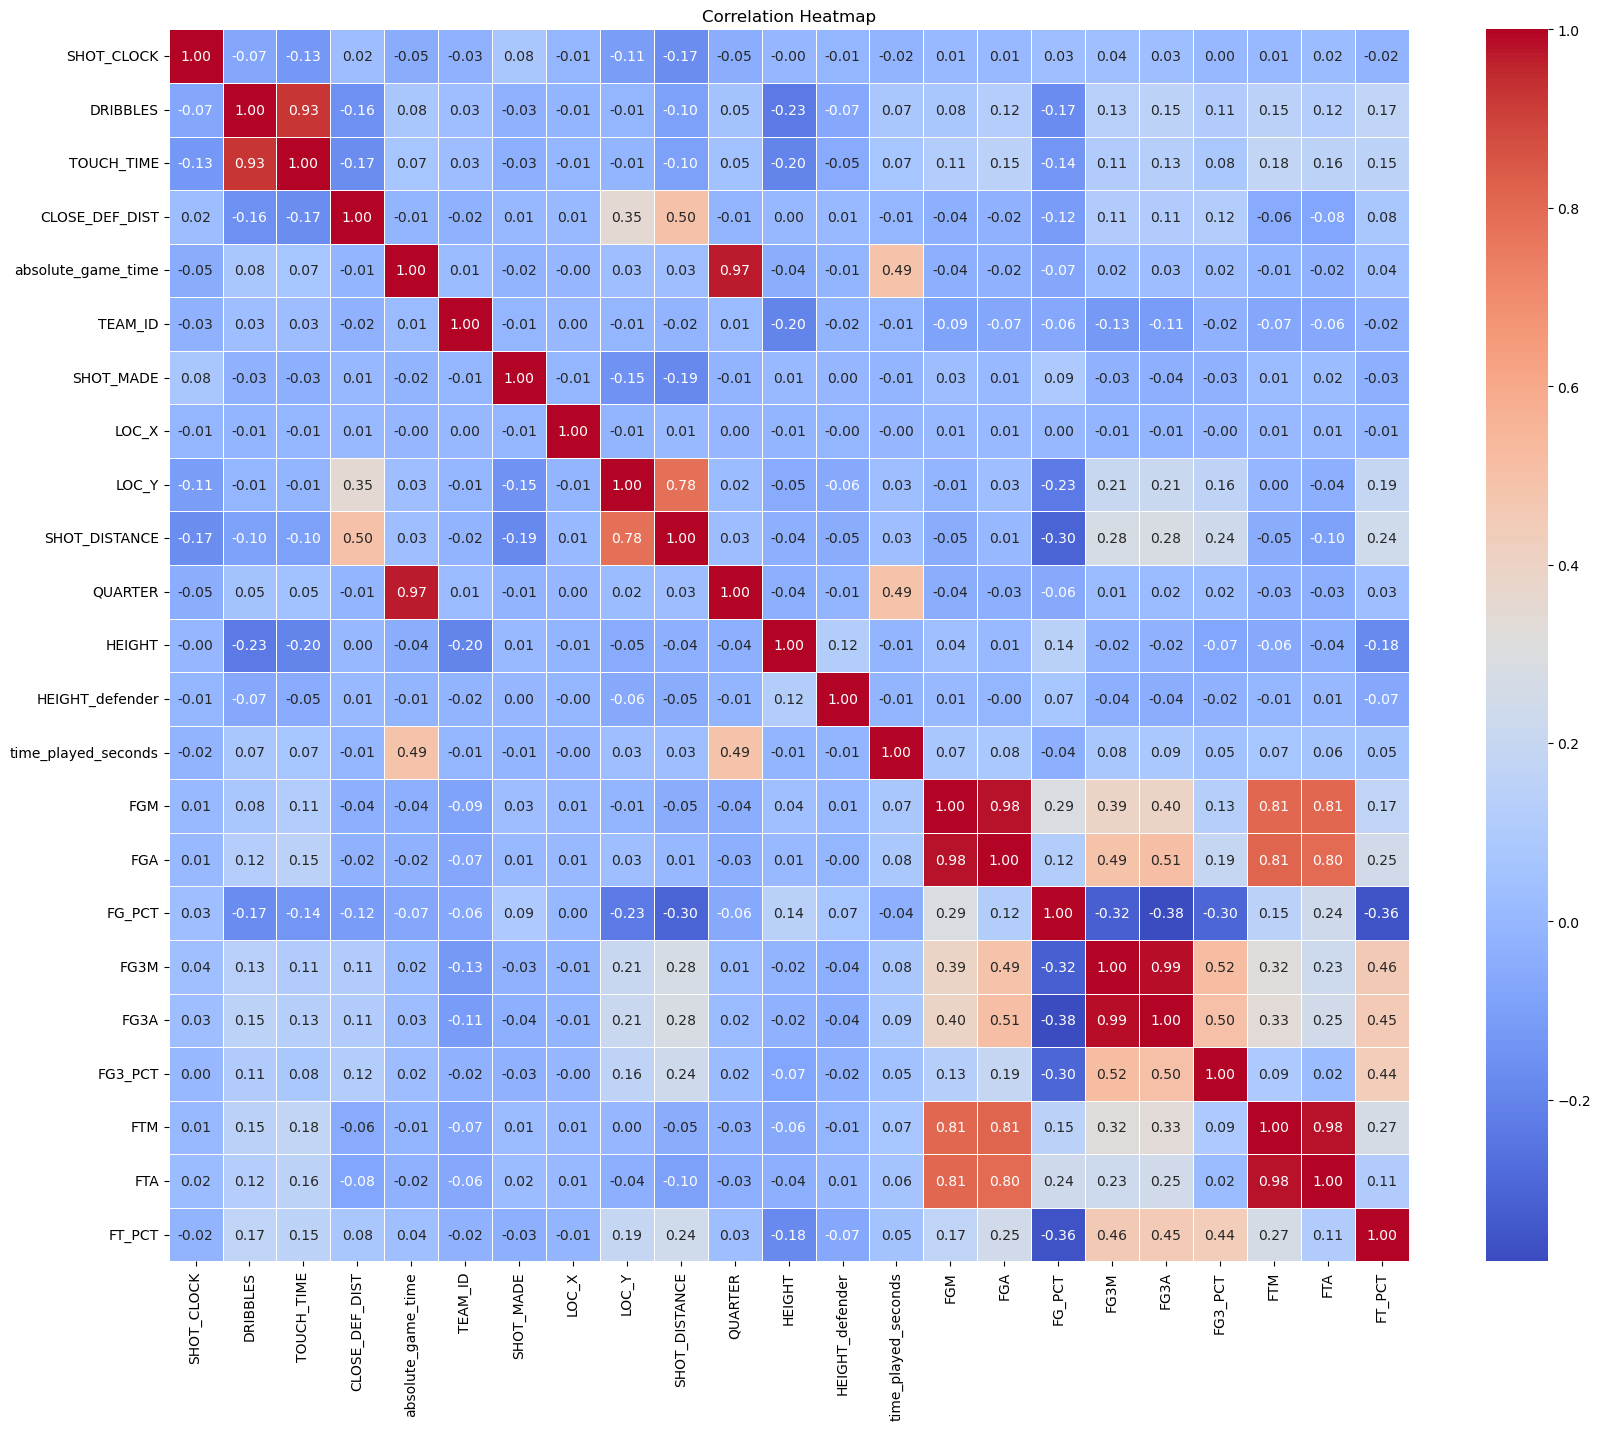

In [128]:
visualize_heatmap(for_pred, numerical_cols)

Example of strong positive correlation from heatmap:  
    FGM (Field Goals Made) and FGA (Field Goals Attempted) - 0.99.  
  This makes sense because the number of shots made is directly linked to the number of shots attempted.

Example of strong negative correlation from heatmap:  
 FG_PCT (Field Goal Percentage) and FGA (Field Goal Attempts) - (-0.36)  
  This can suggests that as a player takes more shots, their shooting percentage tends to decrease.   
    This could indicate fatigue effects or defensive adjustments.


Visualization :

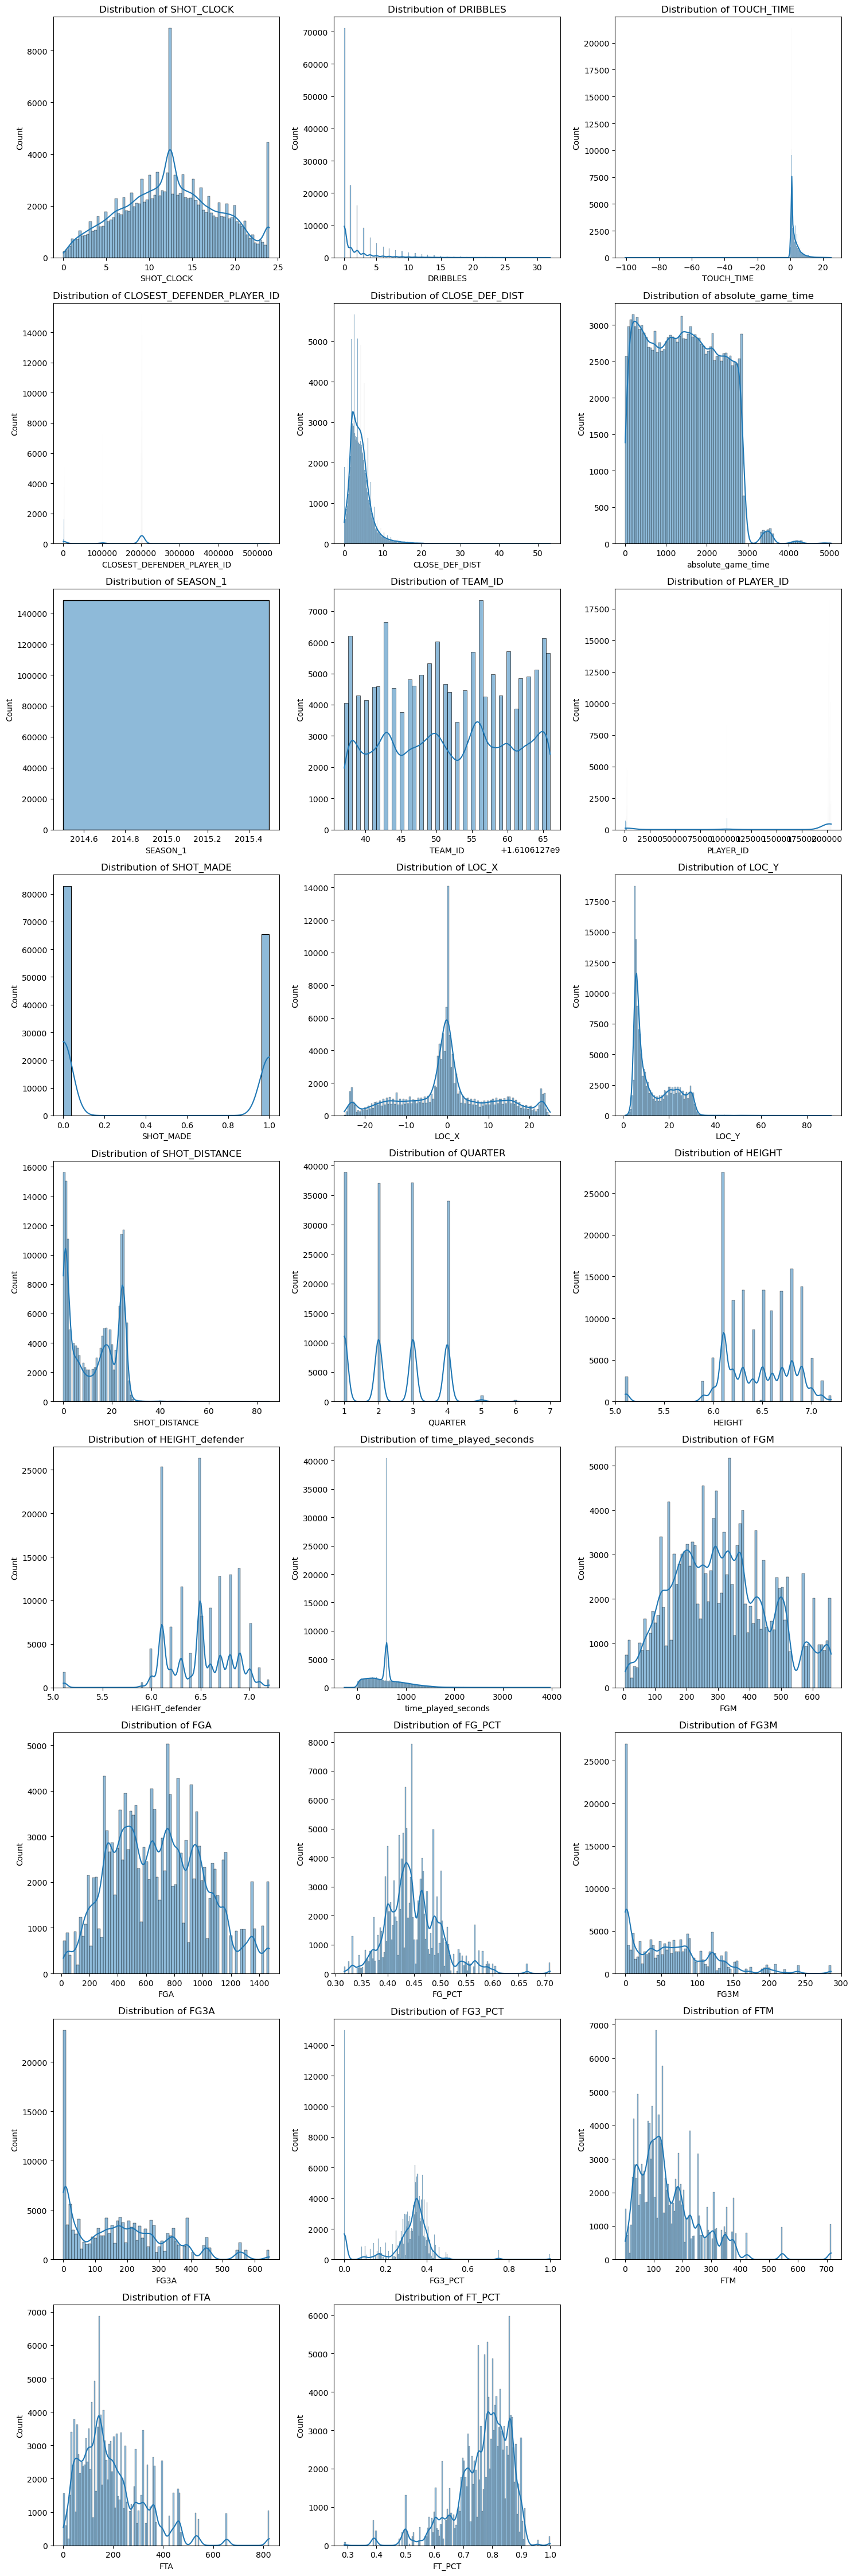

In [132]:
visualize_distributions(for_pred, numerical_cols=for_pred.columns)

### Key Observations:  
SHOT_CLOCK: The distribution likely shows a peak around certain values, possibly near the beginning and end of shot clock periods.  
If there are many shots taken at the last seconds of the shot clock, the distribution might be right-skewed.  
DRIBBLES: This feature may be skewed, with a high number of shots occurring after very few dribbles,  
while fewer occur after many dribbles.  
TOUCH_TIME: A right-skewed distribution is expected, as most shots are taken quickly (low touch time),  
while a smaller number of shots involve longer possession.  
CLOSE_DEF_DIST (Defender Distance): The distribution likely shows a peak around 3-6 feet,  
representing typical contested shots, with a long tail for open shots.  
absolute_game_time: This should have a nearly uniform or right-skewed distribution, with fewer shots at the beginning and more as the game  
rogresses.  
SHOT_DISTANCE: This might be bimodal or right-skewed, with peaks at common shooting distances.  
FGM, FGA, FG_PCT: A strong correlation is expected between shots attempted and made.  
FG% values likely center around common shooting percentages.  
FG3M, FG3A, FG3_PCT: These may show a similar relationship, indicating shot selection and efficiency from beyond the arc.  
FTM, FTA, FT_PCT: Likely normally distributed with a high concentration of free throw percentages around 70-90%.


Reloads the du module and calls du.missing_values_summary(for_pred) to generate a summary of missing values in for_pred : 

In [135]:
importlib.reload(du)
missing_summary = du.missing_values_summary(for_pred)
print(missing_summary)

Empty DataFrame
Columns: [Missing Values, Percentage]
Index: []


check for duplicate rows :

In [137]:
# check for duplicate rows in the data for prediction
duplicate_rows = for_pred[for_pred.duplicated()]

# display the duplicate rows
print(duplicate_rows)


        SHOT_CLOCK  DRIBBLES  TOUCH_TIME  CLOSEST_DEFENDER_PLAYER_ID  \
2194          24.0         0         0.0                      101187   
8032          24.0         0         0.0                        2561   
23571         22.5         0         0.0                      201959   
72128         10.0         0         0.0                      202694   
95863         24.0         0         0.0                      203096   
113995         8.5         0         1.0                        2210   
114335        21.5         2         2.5                      201572   
120832        11.6         3         5.7                      203475   
120833        11.6         3         5.7                      203475   
120834        11.6         3         5.7                      203475   
123718        12.0         2         3.3                        2747   
125500        17.0         0         0.9                        2747   
125595        13.5         3         5.7                        

Remove duplicate rows from for_pred : 

In [139]:
for_pred = for_pred.drop_duplicates().reset_index(drop=True)

Check for constant columns :

In [141]:
constant_columns = du.find_constant_columns(for_pred)
print("Columns with constant values:", constant_columns)

Found 1 constant columns
Columns with constant values: ['SEASON_1']


Drop the constant columns :

In [143]:
for_pred = for_pred.drop(columns=constant_columns)

In [144]:
for_pred.head()

,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,absolute_game_time,TEAM_ID,PLAYER_ID,SHOT_MADE,LOC_X,...,time_played_seconds,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT
0,22.0,2,1.8,202709,2.3,3.0,1.610613e+09,2754,0,-0.6,...,601.059167,225,455,0.495,10,29,0.345,79,126,0.627
1,22.5,2,2.5,201960,3.5,4.0,1.610613e+09,2772,1,-2.4,...,601.059167,366,910,0.402,194,555,0.350,122,143,0.853
2,21.8,3,3.2,201565,5.3,4.0,1.610613e+09,202693,1,1.5,...,601.059167,512,1100,0.465,57,179,0.318,177,232,0.763
3,21.1,0,1.3,203095,3.4,4.0,1.610613e+09,203463,1,-2.2,...,601.059167,363,831,0.437,140,391,0.358,130,160,0.813
4,20.6,0,0.0,201586,4.0,4.0,1.610613e+09,202693,1,-0.0,...,601.059167,512,1100,0.465,57,179,0.318,177,232,0.763


## Prepare the data for prediction:

Defind SHOT_MADE as a taget column :

In [147]:
target_column = 'SHOT_MADE'

Check the distribution of SHOT_MADE :

<Axes: ylabel='count'>

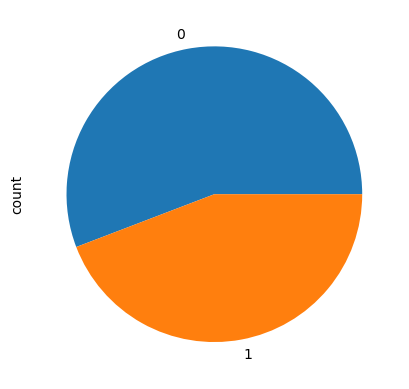

In [149]:
for_pred['SHOT_MADE'].value_counts().plot(kind='pie')

Separates the features (X) and the target variable (y) for model training : 

In [151]:
X = for_pred.drop(target_column, axis=1)
y = for_pred[target_column]

In [152]:
y

0         0
1         1
2         1
3         1
4         1
         ..
148201    0
148202    0
148203    0
148204    0
148205    0
Name: SHOT_MADE, Length: 148206, dtype: int64

In [153]:
X.head()

,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,absolute_game_time,TEAM_ID,PLAYER_ID,LOC_X,LOC_Y,...,time_played_seconds,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT
0,22.0,2,1.8,202709,2.3,3.0,1.610613e+09,2754,-0.6,5.35,...,601.059167,225,455,0.495,10,29,0.345,79,126,0.627
1,22.5,2,2.5,201960,3.5,4.0,1.610613e+09,2772,-2.4,5.05,...,601.059167,366,910,0.402,194,555,0.350,122,143,0.853
2,21.8,3,3.2,201565,5.3,4.0,1.610613e+09,202693,1.5,6.45,...,601.059167,512,1100,0.465,57,179,0.318,177,232,0.763
3,21.1,0,1.3,203095,3.4,4.0,1.610613e+09,203463,-2.2,6.65,...,601.059167,363,831,0.437,140,391,0.358,130,160,0.813
4,20.6,0,0.0,201586,4.0,4.0,1.610613e+09,202693,-0.0,5.35,...,601.059167,512,1100,0.465,57,179,0.318,177,232,0.763


In [154]:
X.columns

Index(['SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER_PLAYER_ID',
       'CLOSE_DEF_DIST', 'absolute_game_time', 'TEAM_ID', 'PLAYER_ID', 'LOC_X',
       'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'HEIGHT', 'HEIGHT_defender',
       'time_played_seconds', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A',
       'FG3_PCT', 'FTM', 'FTA', 'FT_PCT'],
      dtype='object')

Separate numerical and categorical features in the dataset:

In [156]:
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object']).columns

Ensuring that all features are classified correctly before further preprocessing, check that all the columns are numerical or categorical :

In [158]:
all_columns = set(X.columns)
numerical_and_categorical = set(numerical_cols).union(set(categorical_cols))
other_columns = all_columns - numerical_and_categorical

print("Columns that are not in numerical or categorical:")
print(other_columns)

Columns that are not in numerical or categorical:
set()


Handle missing values:  
  fills missing values in numerical columns using the mean value of each column :

In [160]:
num_imputer = SimpleImputer(strategy='mean')
X[numerical_cols] = num_imputer.fit_transform(X[numerical_cols])

Encode categorical features into numerical values using LabelEncoder, which converts each unique category into an integer : 

In [162]:
encoders = {}
for col in categorical_cols:
    encoders[col] = LabelEncoder()
    X[col] = encoders[col].fit_transform(X[col])

Standardizes numerical features by scaling them to have a mean of 0 and a standard deviation of 1 using StandardScaler :

In [164]:
# Scale numerical features
scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols]) # zero mean and unit variance for the numerical columns

In [165]:
X.head()

,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,absolute_game_time,TEAM_ID,PLAYER_ID,LOC_X,LOC_Y,...,time_played_seconds,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT
0,1.698271,-0.038732,-0.341960,0.552940,-0.658734,-1.678407,1.289308,-1.993054,-0.053283,-0.925208,...,0.002708,-0.562245,-0.715275,0.866176,-0.952135,-1.026439,0.330812,-0.663418,-0.516568,-1.521742
1,1.787231,-0.038732,-0.112760,0.543423,-0.221244,-1.677231,-0.778393,-1.992825,-0.217324,-0.959312,...,0.002708,0.360042,0.682676,-0.890106,2.302821,2.556816,0.370084,-0.269539,-0.388781,0.872956
2,1.662688,0.239817,0.116440,0.538405,0.434992,-1.677231,0.485202,0.555559,0.138097,-0.800160,...,0.002708,1.315034,1.266436,0.299634,-0.120706,-0.004598,0.118739,0.234258,0.280222,-0.080685
3,1.538144,-0.595831,-0.505674,0.557845,-0.257701,-1.677231,0.714946,0.565374,-0.199097,-0.777424,...,0.002708,0.340419,0.439955,-0.229139,1.347562,1.439604,0.432921,-0.196260,-0.260994,0.449116
4,1.449184,-0.595831,-0.931332,0.538671,-0.038956,-1.677231,0.485202,0.555559,0.001397,-0.925208,...,0.002708,1.315034,1.266436,0.299634,-0.120706,-0.004598,0.118739,0.234258,0.280222,-0.080685


Split the dataset into training, validation, and test sets, ensuring the model is properly trained and evaluated: 

In [459]:
X_train, X_val, X_test, y_train, y_val, y_test = du.split_dataset(X, y, test_size=0.1, validation_size=0.2, random_state=2312)

save X_train columns for using in future: 

In [461]:
features_names = X_train.columns

In [170]:
X_train.columns

Index(['SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'CLOSEST_DEFENDER_PLAYER_ID',
       'CLOSE_DEF_DIST', 'absolute_game_time', 'TEAM_ID', 'PLAYER_ID', 'LOC_X',
       'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'HEIGHT', 'HEIGHT_defender',
       'time_played_seconds', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A',
       'FG3_PCT', 'FTM', 'FTA', 'FT_PCT'],
      dtype='object')

Remove rows with missing values from X_train:

In [172]:
X_train.dropna()

,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,absolute_game_time,TEAM_ID,PLAYER_ID,LOC_X,LOC_Y,...,time_played_seconds,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT
124740,1.484768,0.518367,0.443869,-1.992167,-1.278512,1.160592,-0.548649,0.535967,-0.153530,-1.084360,...,1.120757,-0.895838,-0.650754,-1.569957,0.339234,0.308767,0.519321,-0.177940,-0.351196,1.286200
102827,-0.009757,-0.595831,-0.702132,0.548061,0.143332,0.629015,-0.778393,-2.004055,-2.222261,-0.868368,...,0.402892,-0.804264,-0.742927,-0.512411,1.099903,0.976369,0.684266,-1.029816,-1.102884,0.449116
93034,1.769439,-0.317282,-0.145503,0.538557,-1.132682,0.402036,-1.008138,0.551684,0.220117,-0.925208,...,1.413426,0.019908,-0.374236,1.999261,-1.093655,-1.183121,0.236557,0.032739,0.159952,-0.557505
100347,0.630753,-0.595831,-0.669389,0.533297,2.148495,0.570212,0.714946,0.565374,1.742046,0.848201,...,-1.179173,0.340419,0.439955,-0.229139,1.347562,1.439604,0.432921,-0.196260,-0.260994,0.449116
113846,0.986593,1.075466,1.000498,0.533284,0.544364,0.888923,1.633925,0.551697,1.341059,1.530281,...,0.168205,-1.098611,-0.890403,-1.702150,-0.439125,-0.317962,-0.077625,-0.580978,-0.696973,0.978916
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117821,-1.842330,-0.038732,-0.145503,-1.991786,-0.585819,0.988888,0.600074,-1.995667,0.046963,-0.527328,...,-0.292885,-0.182864,-0.426467,1.243871,-1.129035,-1.223995,-2.379008,-0.727537,-0.696973,-0.684657
120281,-0.739228,-0.595831,-0.865846,0.557629,-0.367074,1.050042,-1.697372,0.535801,0.001397,-0.925208,...,2.307996,1.360822,0.851659,1.678220,-0.934445,-0.978753,0.024484,-0.406939,-0.403814,-0.123069
113931,-0.383389,-0.595831,-0.276474,0.533132,-0.549361,0.891275,0.714946,0.536158,0.211004,-0.743320,...,-0.712560,-0.791182,-0.979503,1.243871,-1.129035,-1.223995,-2.379008,-0.260379,-0.336163,0.523288
13622,0.346082,-0.595831,-0.505674,0.552635,0.033959,-1.384393,-1.467627,0.551684,0.001397,-0.925208,...,0.002708,0.019908,-0.374236,1.999261,-1.093655,-1.183121,0.236557,0.032739,0.159952,-0.557505


Ensures that the target variables are stored as integers :

In [174]:
y_train = y_train.astype(int)
y_val = y_val.astype(int)
y_test = y_test.astype(int)

## Model Training and Evaluation: Comparing Machine Learning Algorithms

### Logistic regression using L2 and L1 regularizations:  
 L1 and L2 regularization are techniques used in logistic regression to prevent overfitting by adding a penalty term to the loss function.

L1 Regularization (Lasso) adds the absolute values of the coefficients (|β|) as a penalty. This encourages sparsity, meaning some coefficients become exactly zero, effectively performing feature selection. L1 is useful when we suspect that only a few features are truly important.

L2 Regularization (Ridge) adds the squared values of the coefficients (β²) as a penalty. This discourages large coefficients but does not force them to zero, meaning all features still contribute to the model. L2 is useful when all features contain some predictive power but need to be scaled down to avoid overfitting.

Key Differences:  
    L1 results in sparse models (some features eliminated), while L2 retains all features.  
       L1 is better for feature selection, while L2 is better for handling multicollinearity.  
                    L2 generally leads to smoother, more stable models, whereas L1 can produce sharper feature selection. 

Initializes and trains two Logistic Regression models:

In [178]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

# Initialize the logistic regression model with L2 regularization
logistic_model_l2 = LogisticRegression(max_iter=1000, random_state=2312)
logistic_model_l1 = LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=2312)

# Fit the model on the training data
logistic_model_l2.fit(X_train, y_train)
logistic_model_l1.fit(X_train, y_train)

LogisticRegression(max_iter=1000, penalty='l1', random_state=2312,
                   solver='liblinear')

Accuracy scores of two logistic regression models on the training set:

In [180]:
print(logistic_model_l2.score(X_train, y_train),logistic_model_l1.score(X_train, y_train))

0.6130655620946883 0.6130468193574989


Defind val and test variables :

In [182]:
y_val_pred_l2 = logistic_model_l2.predict(X_val)
y_val_pred_l1 = logistic_model_l1.predict(X_val)

In [183]:
y_test_pred_l2 = logistic_model_l2.predict(X_test)
y_test_pred_l1 = logistic_model_l1.predict(X_test)

Calculate the accuracy of validation set :

In [185]:
accuracy_score(y_val, y_val_pred_l2), accuracy_score(y_val, y_val_pred_l1)

(0.6138621284252352, 0.6138246429508566)

Calculate the accuracy of test set :

In [187]:
accuracy_score(y_test, y_test_pred_l2), accuracy_score(y_test, y_test_pred_l1)

(0.608056136562985, 0.6076513055799204)

Accuracy: 0.6139
Precision: 0.5837
Recall: 0.4353
F1 Score: 0.4987
ROC AUC: 0.5951


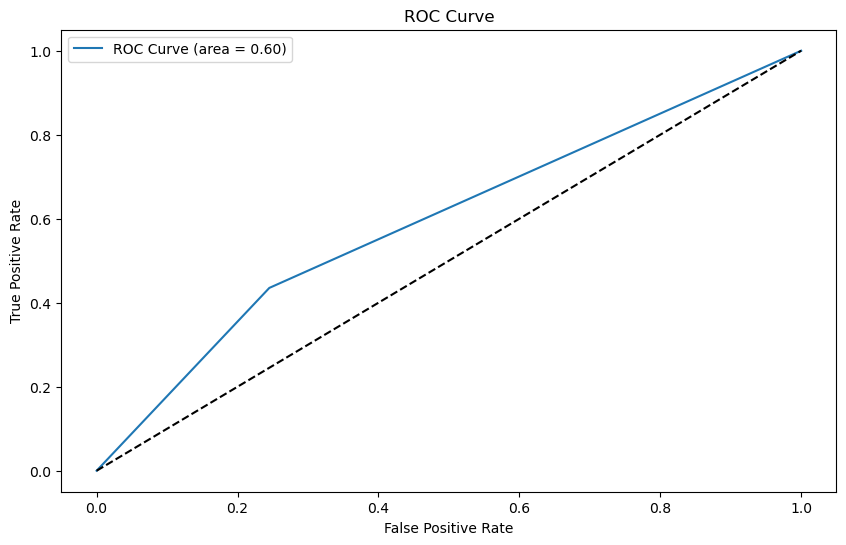

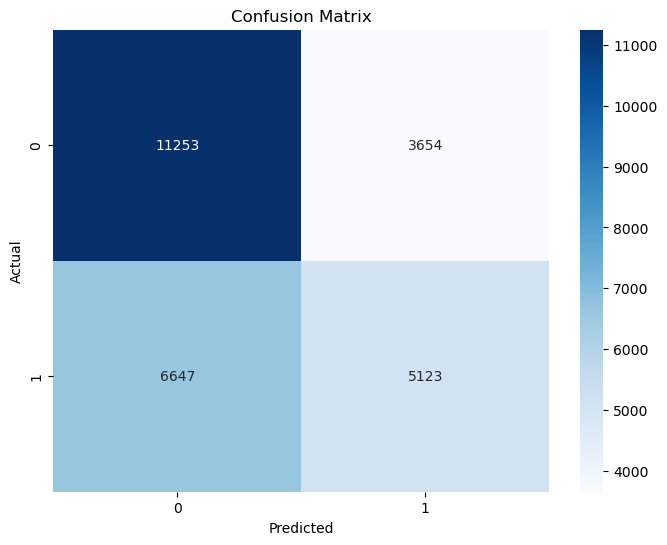

In [188]:
# Calculate metrics for l2
accuracy = accuracy_score(y_val, y_val_pred_l2)
precision = precision_score(y_val, y_val_pred_l2)
recall = recall_score(y_val, y_val_pred_l2)
f1 = f1_score(y_val, y_val_pred_l2)
roc_auc = roc_auc_score(y_val, y_val_pred_l2)

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_val, y_val_pred_l2)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()

# Plot confusion matrix
conf_matrix = confusion_matrix(y_val, y_val_pred_l2)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

conclusions l2 Matrix on the validation set :

False Negatives (Missed shots classified as missed correctly) are relatively high.   
    False Positives (Missed shots wrongly classified as made) seem frequent.  
        This can indicate that the model is likely too conservative in predicting successful shots and often misclassifies them as misses.



Accuracy: 0.6138
Precision: 0.5835
Recall: 0.4359
F1 Score: 0.4990
ROC AUC: 0.5951


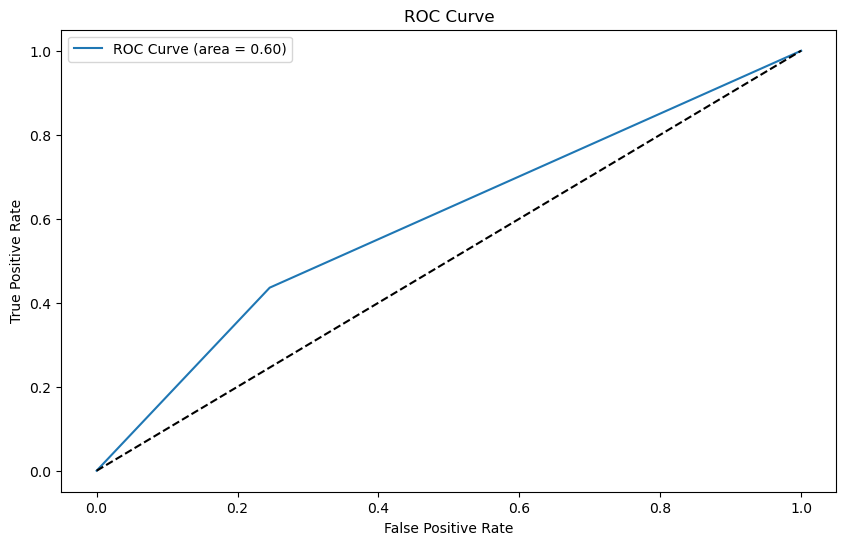

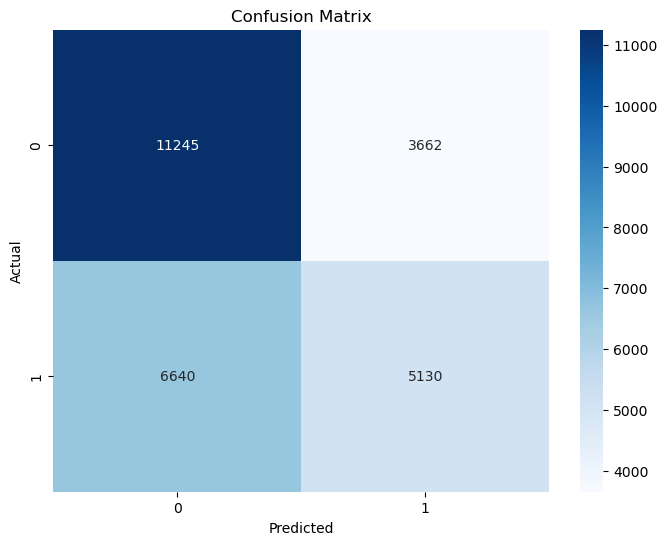

In [190]:
# Calculate metrics for l1
accuracy = accuracy_score(y_val, y_val_pred_l1)
precision = precision_score(y_val, y_val_pred_l1)
recall = recall_score(y_val, y_val_pred_l1)
f1 = f1_score(y_val, y_val_pred_l1)
roc_auc = roc_auc_score(y_val, y_val_pred_l1)

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_val, y_val_pred_l1)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()

# Plot confusion matrix
conf_matrix = confusion_matrix(y_val, y_val_pred_l1)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

l1 matrix on the validation set get the same results as l2 .

In [192]:
y_test_pred_l2 = logistic_model_l2.predict(X_test)
y_test_pred_l1 = logistic_model_l1.predict(X_test)

In [193]:
y_test_proba_l2 = logistic_model_l2.predict_proba(X_test)[:, 1]
y_test_proba_l1 = logistic_model_l1.predict_proba(X_test)[:, 1]

The difference between predict() and predict_proba() is that predict() returns class labels (0 or 1), while predict_proba() returns probability scores for each class ,in this case: returns the predicted probability that each shot was made (1) .

In [195]:
accuracy_l2 = accuracy_score(y_test, y_test_pred_l2)
precision_l2 = precision_score(y_test, y_test_pred_l2)
recall_l2 = recall_score(y_test, y_test_pred_l2)
f1_l2 = f1_score(y_test, y_test_pred_l2)
roc_auc_l2 = roc_auc_score(y_test, y_test_proba_l2)

In [196]:
print("\n**Logistic Regression - L2 Regularization** 📊")
print(f"Accuracy: {accuracy_l2:.4f}")
print(f"Precision: {precision_l2:.4f}")
print(f"Recall: {recall_l2:.4f}")
print(f"F1 Score: {f1_l2:.4f}")
print(f"ROC AUC: {roc_auc_l2:.4f}")


**Logistic Regression - L2 Regularization** 📊
Accuracy: 0.6081
Precision: 0.5806
Recall: 0.4381
F1 Score: 0.4994
ROC AUC: 0.6272


In [197]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred_l2))

              precision    recall  f1-score   support

           0       0.62      0.75      0.68      8208
           1       0.58      0.44      0.50      6613

    accuracy                           0.61     14821
   macro avg       0.60      0.59      0.59     14821
weighted avg       0.60      0.61      0.60     14821



conclusions l2 Matrix on the test set :  
    the model is better at detecting missed shots than successful ones.   
      Since recall is high (0.75), the model is less likely to mistakenly classify a missed shot as made.

In [199]:
fpr_l2, tpr_l2, _ = roc_curve(y_test, y_test_proba_l2)

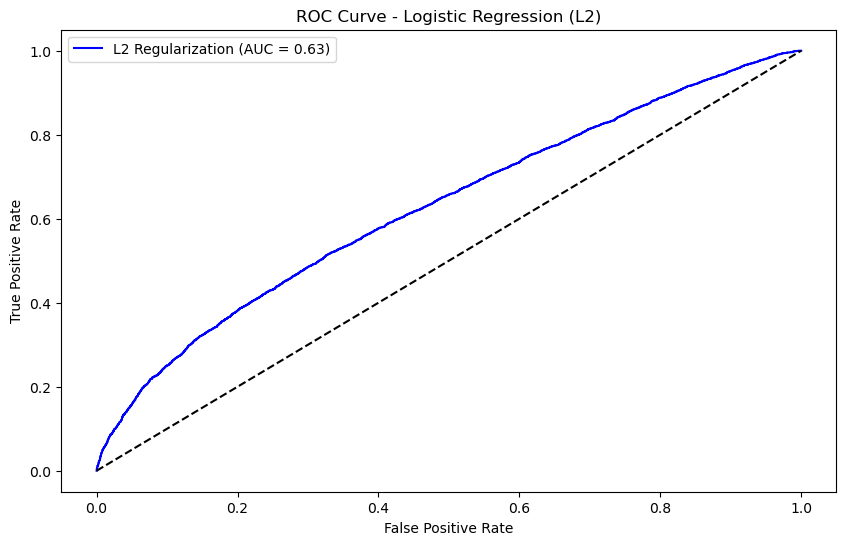

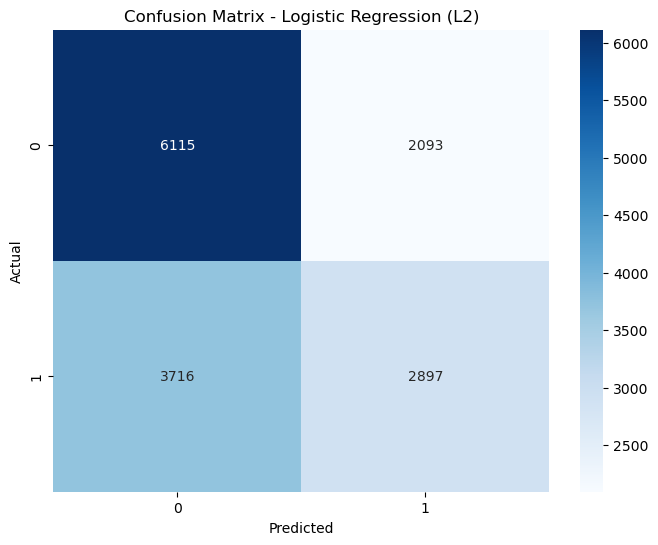

In [200]:
plt.figure(figsize=(10, 6))
plt.plot(fpr_l2, tpr_l2, label=f'L2 Regularization (AUC = {roc_auc_l2:.2f})', color='blue')
plt.plot([0, 1], [0, 1], 'k--')  #random line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression (L2)')
plt.legend(loc='best')
plt.show()


conf_matrix_l2 = confusion_matrix(y_test, y_test_pred_l2)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_l2, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression (L2)')
plt.show()

The function classification_report_with_threshold() is designed to generate a classification report and confusion matrix while allowing the user to set a custom decision threshold for classification :

In [202]:

def classification_report_with_threshold(y_true, y_proba, threshold=0.4, display_cm=True):

    # Apply threshold to get binary predictions
    y_pred = (y_proba >= threshold).astype(int)
    
    # Print the classification report
    print(f"\nClassification Report (threshold = {threshold}):")
    print(classification_report(y_true, y_pred))
    
    # Calculate and display confusion matrix if requested
    if display_cm:
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
        plt.title(f'Confusion Matrix (threshold = {threshold})')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.show()
    
    return y_pred



In [203]:
accuracy_l1 = accuracy_score(y_test, y_test_pred_l1)
precision_l1 = precision_score(y_test, y_test_pred_l1)
recall_l1 = recall_score(y_test, y_test_pred_l1)
f1_l1 = f1_score(y_test, y_test_pred_l1)
roc_auc_l1 = roc_auc_score(y_test, y_test_proba_l1)

In [204]:
print("\n**Logistic Regression - L1 Regularization** 📊")
print(f"Accuracy: {accuracy_l1:.4f}")
print(f"Precision: {precision_l1:.4f}")
print(f"Recall: {recall_l1:.4f}")
print(f"F1 Score: {f1_l1:.4f}")
print(f"ROC AUC: {roc_auc_l1:.4f}")


**Logistic Regression - L1 Regularization** 📊
Accuracy: 0.6077
Precision: 0.5799
Recall: 0.4379
F1 Score: 0.4990
ROC AUC: 0.6273


In [205]:
print(classification_report(y_test, y_test_pred_l1))

              precision    recall  f1-score   support

           0       0.62      0.74      0.68      8208
           1       0.58      0.44      0.50      6613

    accuracy                           0.61     14821
   macro avg       0.60      0.59      0.59     14821
weighted avg       0.60      0.61      0.60     14821



conclusions l1 Matrix on the test set :  
l1 matrix on the test set get the same results as l2 .

In [207]:
fpr_l1, tpr_l1, _ = roc_curve(y_test, y_test_proba_l1)

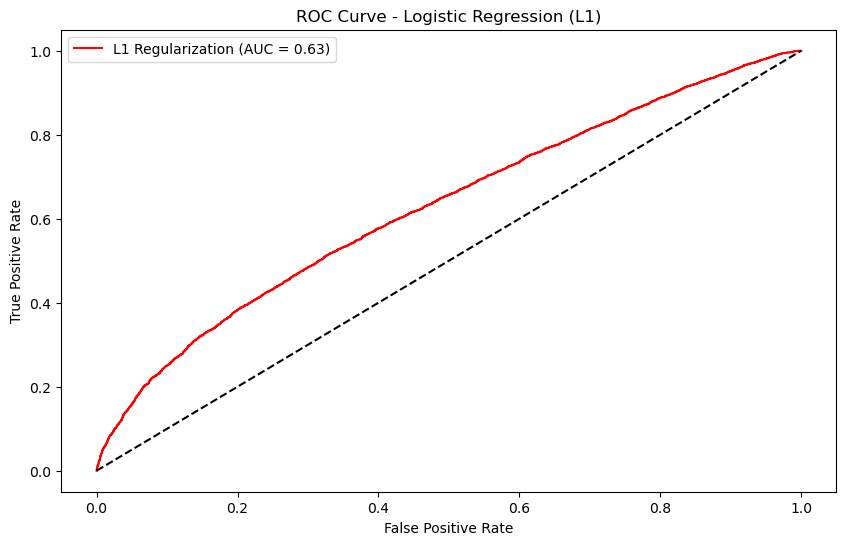

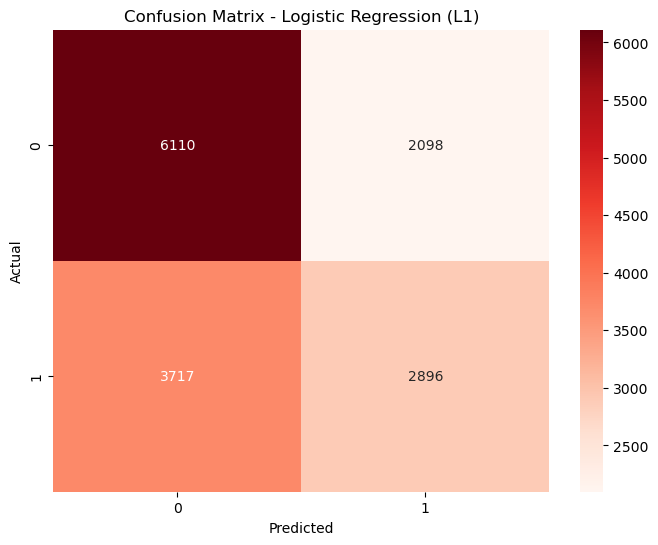

In [208]:
plt.figure(figsize=(10, 6))
plt.plot(fpr_l1, tpr_l1, label=f'L1 Regularization (AUC = {roc_auc_l1:.2f})', color='red')
plt.plot([0, 1], [0, 1], 'k--')  #random line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression (L1)')
plt.legend(loc='best')
plt.show()


conf_matrix_l1 = confusion_matrix(y_test, y_test_pred_l1)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_l1, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression (L1)')
plt.show()

Conclusions Logistic regression :  
The accuracy (62%) is only slightly better than random guessing (50%).  
The ROC AUC (0.60) suggests the models struggle to distinguish between made and missed shots effectively. 
Logistic regression provides a baseline model, but it struggles with complex interactions in shot prediction.

## SVM: 
SVM is a supervised learning algorithm used for classification and regression tasks. It works by finding the optimal hyperplane that best separates different classes in the feature space. In cases where the data is not linearly separable, SVM can use kernel functions  to transform the data into a higher-dimensional space where it becomes more separable.

In [211]:
# check the class balance. if balanced, we don't need to use class_weight='balanced'
y.value_counts()

SHOT_MADE
0    82717
1    65489
Name: count, dtype: int64

Initializes an SVM classifier using sklearn.svm.SVC :

In [213]:
from sklearn import svm

# Initialize the SVM model
svm_model = svm.SVC(random_state=2312, cache_size=800)

Fits the SVM model on the training dataset:

In [215]:
svm_model.fit(X_train, y_train)

SVC(cache_size=800, random_state=2312)

predicts the labels for the validation set:

In [217]:
svm_val_pred = svm_model.predict(X_val)

In [218]:
svm_val_pred

array([0, 0, 0, ..., 0, 0, 0])

In [219]:
accuracy = accuracy_score(y_val, svm_val_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.6270


Evaluate the performance of the SVM model on the validation set using accuracy, precision, recall, F1-score, and ROC-AUC:

Accuracy: 0.6270
Precision: 0.6408
Recall: 0.3517
F1 Score: 0.4542
ROC AUC: 0.5980


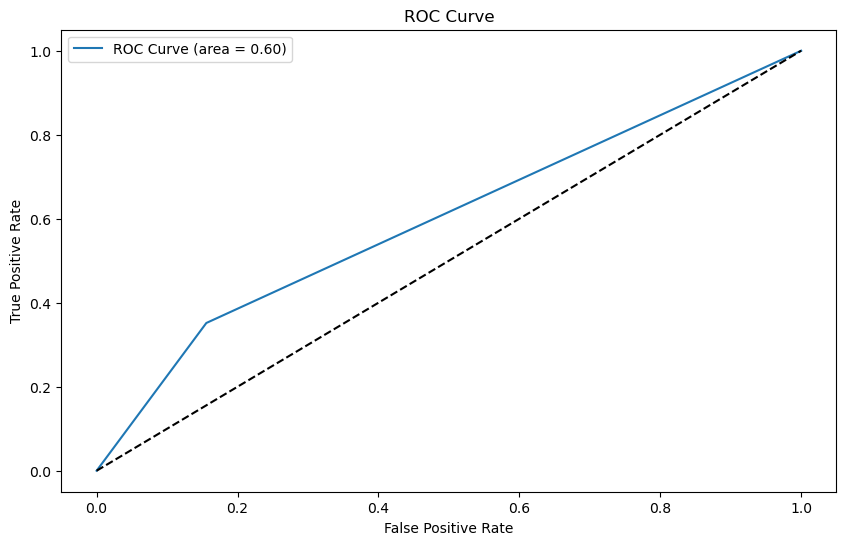

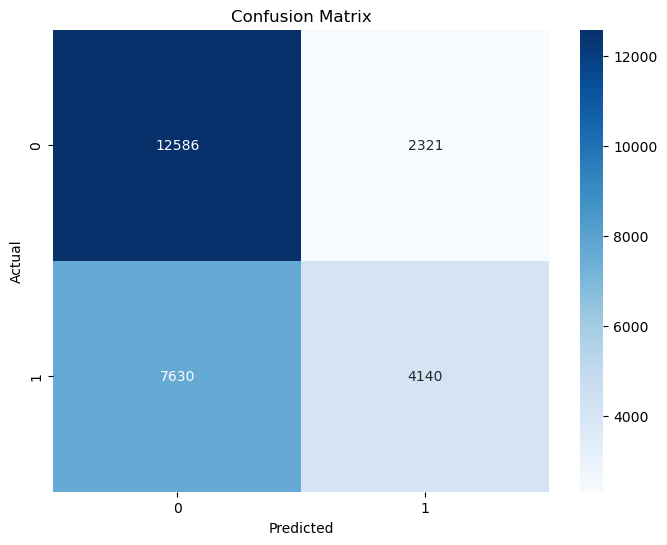

In [221]:
accuracy = accuracy_score(y_val, svm_val_pred)
precision = precision_score(y_val, svm_val_pred)
recall = recall_score(y_val, svm_val_pred)
f1 = f1_score(y_val, svm_val_pred)
roc_auc = roc_auc_score(y_val, svm_val_pred)

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_val, svm_val_pred)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()

# Plot confusion matrix
conf_matrix = confusion_matrix(y_val, svm_val_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Predicts the labels for the test set:

In [223]:
svm_test_pred = svm_model.predict(X_test)

In [224]:
accuracy = accuracy_score(y_test, svm_test_pred)
precision = precision_score(y_test, svm_test_pred)
recall = recall_score(y_test, svm_test_pred)
f1 = f1_score(y_test, svm_test_pred)
roc_auc = roc_auc_score(y_test, svm_test_pred)

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

Accuracy: 0.6253
Precision: 0.6455
Recall: 0.3552
F1 Score: 0.4583
ROC AUC: 0.5990


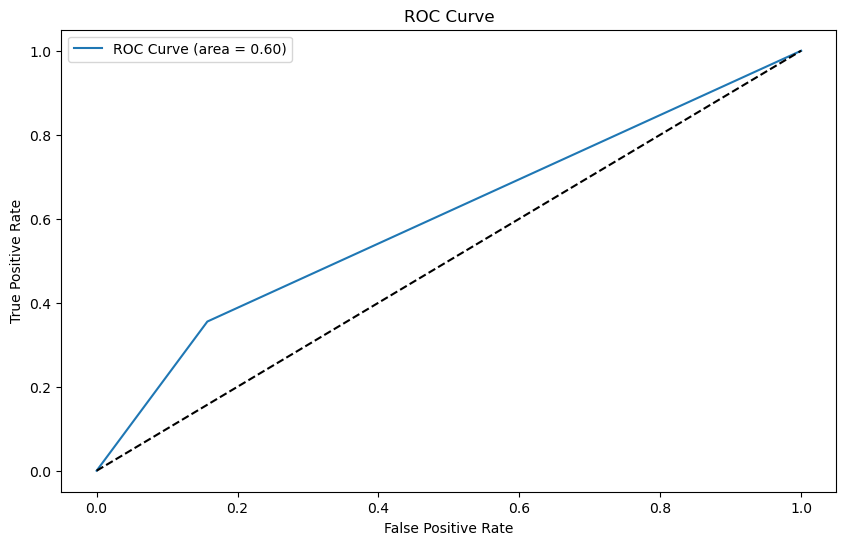

In [225]:
#Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, svm_test_pred)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()

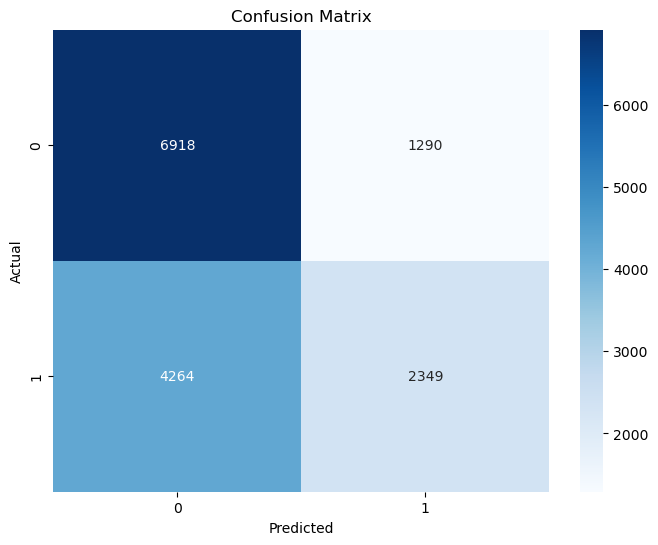

In [226]:

# Plot confusion matrix
conf_matrix = confusion_matrix(y_test, svm_test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Conclusions SVM : The SVM model achieved moderate results on the shot prediction task. 
On the test set it attained about 62.53% accuracy, with 64.55% precision and 35.52% recall for predicting made shots.
This indicates that while the SVM was fairly accurate overall , it identified barely over one-third of actual made shots (low recall) – it tended to be conservative in predicting a shot would be made. 
SVM proved to be robust in overall accuracy – it slightly outperformed the baseline logistic regression in accuracy , However, the SVM showed a major weakness in recall. in addition SVMs are computationally expensive on larger datasets. 
Given its middling performance and practical downsides, the SVM is not the top choice for this NBA shot prediction task. Its slight accuracy gain over logistic regression doesn’t outweigh the much lower recall, and the model is less interpretable and more resource-intensive.

##  RANDOM FOREST:   
  Random Forest is an ensemble learning algorithm that builds multiple decision trees and combines their predictions to improve accuracy and reduce overfitting. Each tree is trained on a random subset of the data using a technique called bagging , which helps the model generalize well to new data. The final prediction is determined by majority voting (for classification) or averaging (for regression).

In [229]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
random_forest_model = RandomForestClassifier(random_state=2312, n_estimators=200)

Fits the RF model on the training dataset:

In [231]:
random_forest_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=2312)

Generates predictions for the validation set using the trained Random Forest model:

In [233]:
val_rf_pred = random_forest_model.predict(X_val)

In [234]:
accuracy = accuracy_score(y_val, val_rf_pred)
precision = precision_score(y_val, val_rf_pred)
recall = recall_score(y_val, val_rf_pred)
f1 = f1_score(y_val, val_rf_pred)
roc_auc = roc_auc_score(y_val, val_rf_pred)

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print(classification_report(y_val, val_rf_pred))

Accuracy: 0.6745
Precision: 0.7068
Recall: 0.4483
F1 Score: 0.5486
ROC AUC: 0.6507
              precision    recall  f1-score   support

           0       0.66      0.85      0.75     14907
           1       0.71      0.45      0.55     11770

    accuracy                           0.67     26677
   macro avg       0.68      0.65      0.65     26677
weighted avg       0.68      0.67      0.66     26677



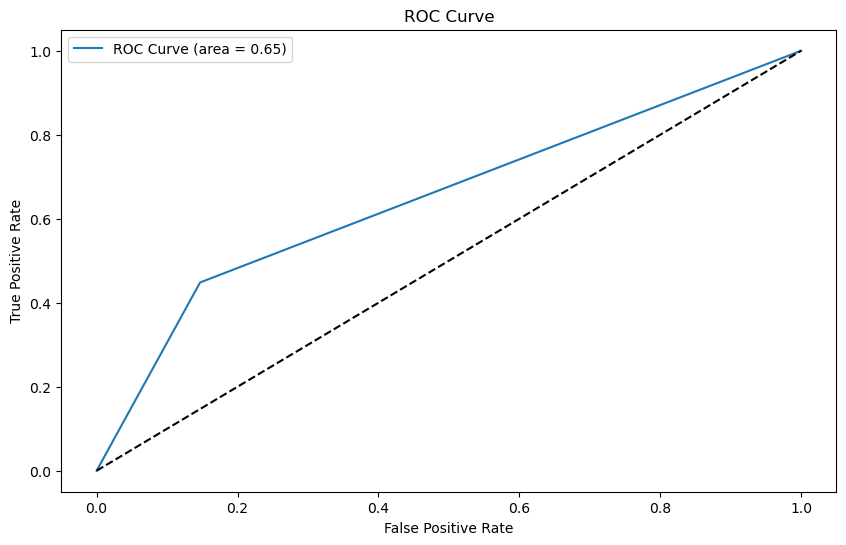

In [235]:
#Plot ROC curve
fpr, tpr, _ = roc_curve(y_val, val_rf_pred)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()

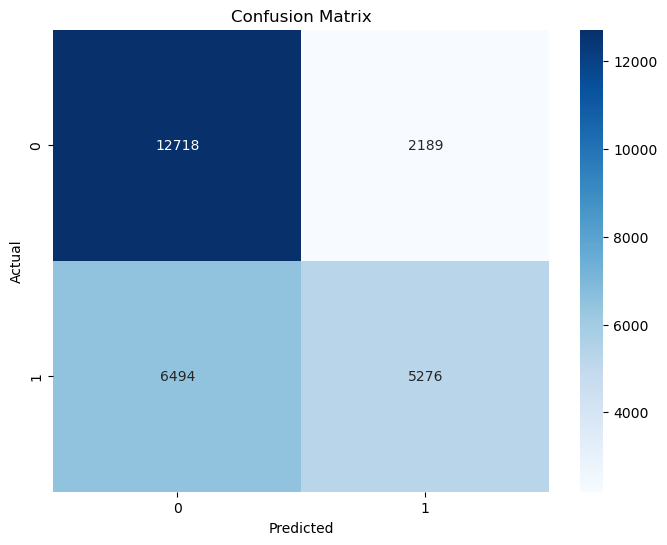

In [236]:

# Plot confusion matrix
conf_matrix = confusion_matrix(y_val, val_rf_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Sorting features by importance :

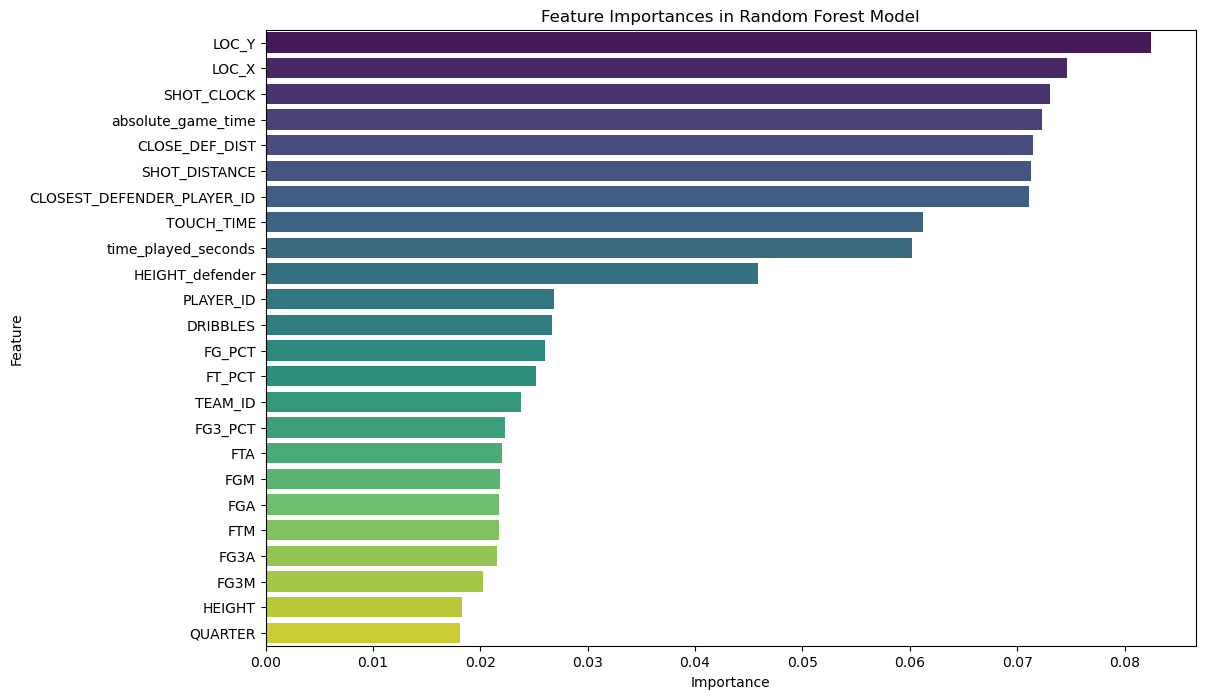

In [465]:
# Get feature importances from the random forest model
importances = random_forest_model.feature_importances_

# Create a DataFrame for better visualization
feature_importances = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances})

# Sort the DataFrame by importance
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importances, hue="Feature", palette='viridis', legend=False)
plt.title('Feature Importances in Random Forest Model')
plt.show()

Conclusions from feature importance :  
spatial positioning (LOC_X and LOC_Y) is the most influential factor in predicting shot outcomes.  
This suggests that the location of the shot plays a crucial role in determining whether it is successful.  
Other highly significant features include SHOT_CLOCK, absolute_game_time, and CLOSE_DEF_DIST, indicating that time constraints and defensive pressure are key determinants of shot success.  
SHOT_DISTANCE is also among the top contributors, highlighting the importance of shot range.  
Notably, TOUCH_TIME and time_played_seconds show moderate importance, suggesting that player fatigue and decision-making speed impact shot accuracy.  
Surprisingly, traditional shooting efficiency metrics such as FG_PCT, FT_PCT, and FG3_PCT hold lower importance, implying that situational and spatial factors may outweigh general shooting ability in the model's decision-making.  
In general, the feature importance makes a lot of sense. However, in my personal opinion, in today's basketball world, the distance of the closest defender to the shot has a greater impact on the shot outcome than the shot distance itself.  
However, the difference shown in the graph is minimal.

In [240]:
y_test_pred_rf = random_forest_model.predict(X_test)

In [241]:
accuracy_rf = accuracy_score(y_test, y_test_pred_rf)
precision_rf = precision_score(y_test, y_test_pred_rf)
recall_rf = recall_score(y_test, y_test_pred_rf)
f1_rf = f1_score(y_test, y_test_pred_rf)
roc_auc_rf = roc_auc_score(y_test, random_forest_model.predict_proba(X_test)[:, 1])

In [242]:
print("\n**Random Forest - Test Metrics** 📊")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1 Score: {f1_rf:.4f}")
print(f"ROC AUC: {roc_auc_rf:.4f}")


**Random Forest - Test Metrics** 📊
Accuracy: 0.6694
Precision: 0.7047
Recall: 0.4459
F1 Score: 0.5462
ROC AUC: 0.7178


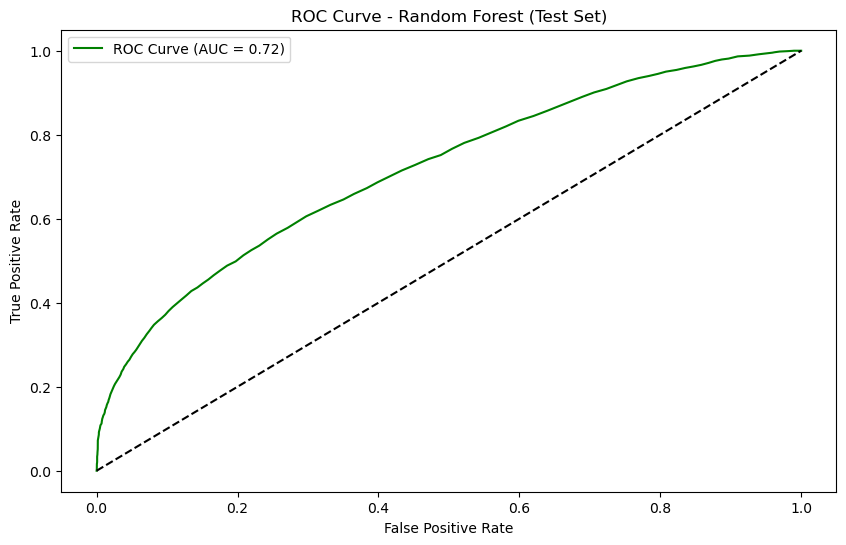

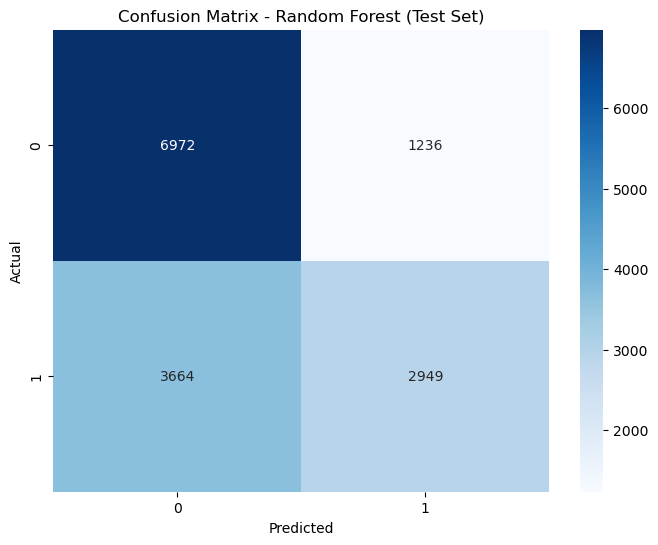

In [243]:
#ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, random_forest_model.predict_proba(X_test)[:, 1])
plt.figure(figsize=(10, 6))
plt.plot(fpr_rf, tpr_rf, label=f'ROC Curve (AUC = {roc_auc_rf:.2f})', color='green')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest (Test Set)')
plt.legend(loc='best')
plt.show()

#Confusion matrix
conf_matrix_rf = confusion_matrix(y_test, y_test_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_rf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest (Test Set)')
plt.show()

Trains and evaluates a Random Forest Classifier using RandomizedSearchCV to optimize hyperparameters. It then makes predictions, evaluates performance, and visualizes feature importance:

Overall Performance: The Random Forest model achieved about 66–67% accuracy on the test set, making it one of the top performers. 
It had a high precision (70%) but moderate recall (45%) for predicting made shots 
This yields an F1-score around 0.54 and the highest ROC AUC (~0.72) among the models,  
indicating Random Forest distinguished made vs. missed shots better than most alternatives.

Training Random Forest with RandomizedSearchCV...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
[CV 2/3] END bootstrap=False, class_weight=None, max_depth=10, max_features=None, min_samples_leaf=4, min_samples_split=10, n_estimators=200;, score=0.628 total time= 9.1min
[CV 1/3] END bootstrap=False, class_weight=balanced_subsample, max_depth=20, max_features=log2, min_samples_leaf=2, min_samples_split=10, n_estimators=100;, score=0.655 total time= 1.5min
[CV 2/3] END bootstrap=False, class_weight=balanced_subsample, max_depth=20, max_features=log2, min_samples_leaf=2, min_samples_split=10, n_estimators=100;, score=0.653 total time= 1.5min
[CV 3/3] END bootstrap=False, class_weight=balanced_subsample, max_depth=20, max_features=log2, min_samples_leaf=2, min_samples_split=10, n_estimators=100;, score=0.650 total time= 1.6min
[CV 1/3] END bootstrap=False, class_weight=balanced, max_depth=20, max_features=log2, min_samples_leaf=4, min_samples_split=5, n_estimators=500;, score=

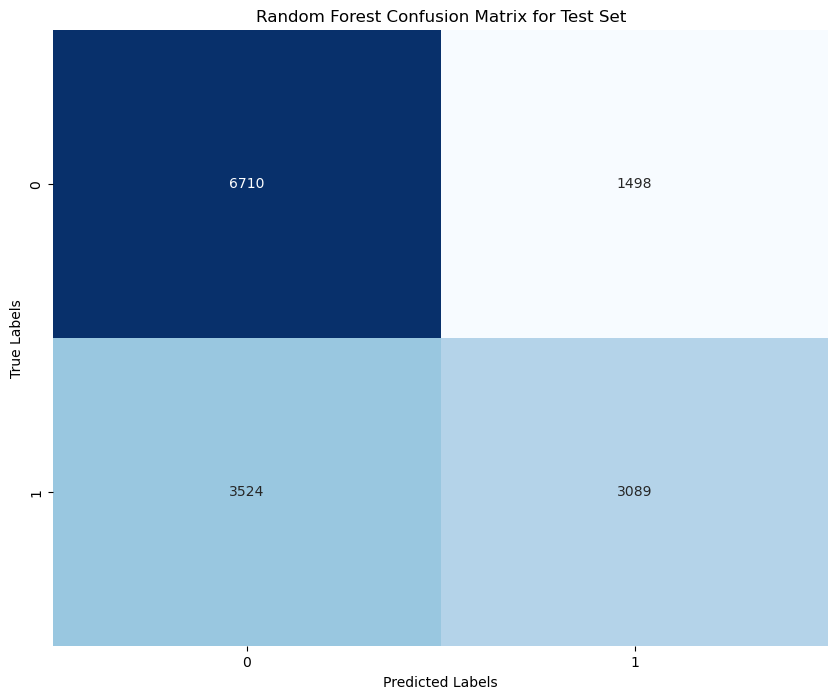


Random Forest Final Accuracy Scores:
Training accuracy: 0.9714
Validation accuracy: 0.6659
Test accuracy: 0.6612


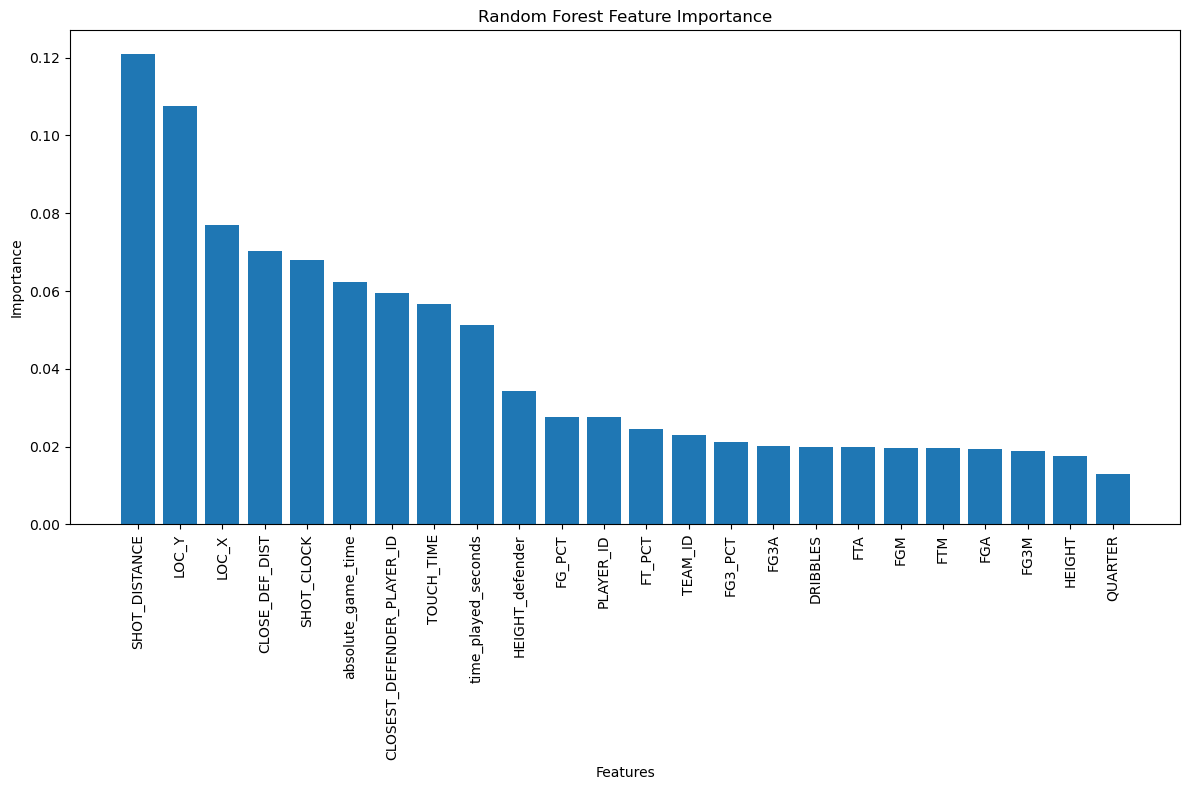

In [246]:
# Define parameter grid for Random Forest random search
rf_param_grid = {
    'n_estimators': [100, 200, 500],
     'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False],
    'class_weight': ['balanced', 'balanced_subsample', None]
}

# Initialize Random Forest model
rf_model = RandomForestClassifier(random_state=42)

# Create RandomizedSearchCV for Random Forest
rf_random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=5,  # Number of parameter settings sampled
    scoring='accuracy',
    cv=3,  # Number of cross-validation folds
    verbose=4,
    random_state=42,
    n_jobs=-1  # Use all available cores
)

# Fit RandomizedSearchCV to the training data
print("Training Random Forest with RandomizedSearchCV...")
rf_random_search.fit(X_train, y_train)

# Get the best parameters and best score
rf_best_params = rf_random_search.best_params_
rf_best_score = rf_random_search.best_score_

print(f"\nRandom Forest Best parameters found: {rf_best_params}")
print(f"Random Forest Best cross-validation score: {rf_best_score:.4f}")

# Train the model with the best parameters
rf_best_model = RandomForestClassifier(**rf_best_params, random_state=42)
rf_best_model.fit(X_train, y_train)

# Make predictions on training, validation, and test sets
rf_y_train_pred = rf_best_model.predict(X_train)
rf_y_val_pred = rf_best_model.predict(X_val)
rf_y_test_pred = rf_best_model.predict(X_test)

# Print classification reports
print("\nRandom Forest Training Set Classification Report:")
print(classification_report(y_train, rf_y_train_pred))

print("\nRandom Forest Validation Set Classification Report:")
print(classification_report(y_val, rf_y_val_pred))

print("\nRandom Forest Test Set Classification Report:")
print(classification_report(y_test, rf_y_test_pred))

# Calculate and plot confusion matrix for test set
rf_cm = confusion_matrix(y_test, rf_y_test_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Random Forest Confusion Matrix for Test Set')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.savefig('random_forest_confusion_matrix.png')
plt.show()

# Calculate and print accuracy for each set
rf_train_accuracy = accuracy_score(y_train, rf_y_train_pred)
rf_val_accuracy = accuracy_score(y_val, rf_y_val_pred)
rf_test_accuracy = accuracy_score(y_test, rf_y_test_pred)

print(f"\nRandom Forest Final Accuracy Scores:")
print(f"Training accuracy: {rf_train_accuracy:.4f}")
print(f"Validation accuracy: {rf_val_accuracy:.4f}")
print(f"Test accuracy: {rf_test_accuracy:.4f}")

# Feature importance visualization
importances = rf_best_model.feature_importances_
#feature_name = np.arange(len(importances))  # Replace with actual feature names if available



# #Sort feature importances in descending order
sorted_idx = np.argsort(importances)[::-1]
sorted_importance = importances[sorted_idx]
sorted_features = features_names[sorted_idx]

plt.figure(figsize=(12, 8))
plt.bar(range(len(sorted_importance)), sorted_importance)
plt.xticks(range(len(sorted_importance)), sorted_features, rotation=90)
plt.title('Random Forest Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.tight_layout()
plt.savefig('random_forest_feature_importance.png')
plt.show()

Feature Importance: Random Forest identified intuitive predictors. 
Shot distance to the basket and defensive pressure (distance of closest defender) emerged as top influences on shot success. 
Player skill metrics also ranked highly, meaning better shooters and closer shots substantially boost predicted success. 
Temporal factors like time remaining or fatigue (time on court) showed smaller effects but still contributed to the model’s decisions

Strengths and Weaknesses: As an ensemble of decision trees, Random Forest captures non-linear interactions without requiring extensive parameter tuning. 
It handled the mix of numerical features well and was less prone to the underfitting seen in simpler models. 
However, it did tend to overfit on training data. 
training accuracy was ~97% vs. ~67% on test – requiring tuning of depth and leaf size to generalize properly.

Conclusions Random Forest : Random Forest provided a significant improvement over simpler models. 
For example, a logistic regression baseline only reached about 61% accuracy. 
Random Forest’s ~67% accuracy and 0.72 AUC demonstrate its better ability to capture the complex interactions. 
In summary, Random Forest’s ensemble approach yielded more robust performance than those simpler or linear models. 
Random Forest is a strong choice for shot prediction if one desires a relatively interpretable ensemble with solid accuracy.


## XGBOOST:
XGBoost (Extreme Gradient Boosting) is a powerful ensemble learning algorithm based on gradient boosting. It builds multiple decision trees sequentially, where each tree corrects the mistakes of the previous one, leading to highly accurate and robust predictions. XGBoost is known for its efficiency, scalability, and strong predictive performance in structured data tasks.

In [251]:
!pip install xgboost

In [252]:
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV

Initializes an XGBoost classification model with optimized hyperparameters, including scale_pos_weight, to handle class imbalance and improve prediction performance:

In [254]:
# Creat model XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,  
    learning_rate=0.1,  
    max_depth=6,  
    subsample=0.8, 
    colsample_bytree=0.8,
    random_state=42,
    #scale positive weight multy 1.5 for balance :
    scale_pos_weight=1.5
)

Convert format from pandas dataframes to numpy input:


In [256]:
# Convert format:
X_train = X_train.values
X_val = X_val.values
X_test = X_test.values
y_train = y_train.values
y_val = y_val.values
y_test = y_test.values

In [257]:
#Training the model XGBoost
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [258]:
y_pred_xgb = xgb_model.predict(X_val)

In [259]:
accuracy = accuracy_score(y_val, y_pred_xgb)
precision = precision_score(y_val, y_pred_xgb)
recall = recall_score(y_val, y_pred_xgb)
f1 = f1_score(y_val, y_pred_xgb)
roc_auc = roc_auc_score(y_val, xgb_model.predict_proba(X_val)[:, 1])
report = classification_report(y_val, y_pred_xgb)

In [260]:
print("\n**XGBoost - Metrics** 📊")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print('Classification Report:')
print(report)


**XGBoost - Metrics** 📊
Accuracy: 0.6100
Precision: 0.5508
Recall: 0.6288
F1 Score: 0.5872
ROC AUC: 0.6704
Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.60      0.63     14907
           1       0.55      0.63      0.59     11770

    accuracy                           0.61     26677
   macro avg       0.61      0.61      0.61     26677
weighted avg       0.62      0.61      0.61     26677



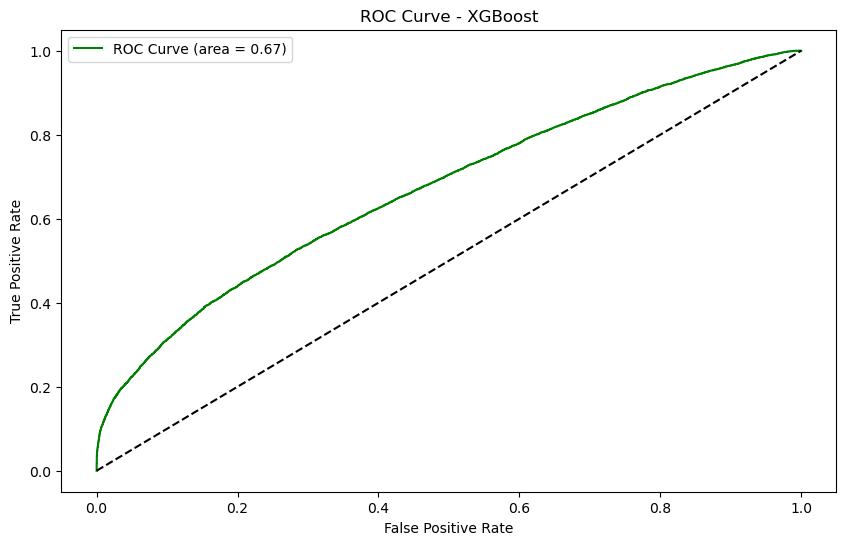

In [261]:
fpr, tpr, _ = roc_curve(y_val, xgb_model.predict_proba(X_val)[:, 1])
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})', color='green')
plt.plot([0, 1], [0, 1], 'k--')  # random line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost')
plt.legend(loc='best')
plt.show()

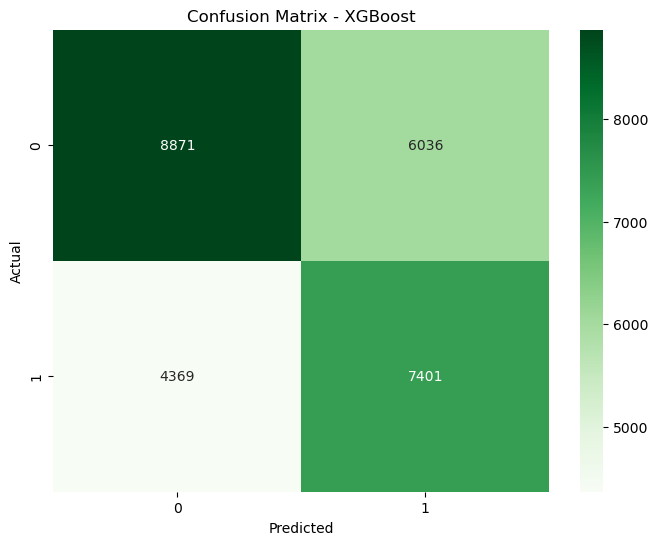

In [262]:
conf_matrix = confusion_matrix(y_val, y_pred_xgb)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.show()

In [263]:
y_test_pred_xgb = xgb_model.predict(X_test)

In [264]:
y_test_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [265]:
accuracy_xgb = accuracy_score(y_test, y_test_pred_xgb)
precision_xgb = precision_score(y_test, y_test_pred_xgb)
recall_xgb = recall_score(y_test, y_test_pred_xgb)
f1_xgb = f1_score(y_test, y_test_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1])
report = classification_report(y_test, y_test_pred_xgb)

In [266]:
print("\n**XGBoost - Test Set Metrics** 📊")
print(f"Accuracy: {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1 Score: {f1_xgb:.4f}")
print(f"ROC AUC: {roc_auc_xgb:.4f}")
print(report)
print(y_test_proba_xgb)


**XGBoost - Test Set Metrics** 📊
Accuracy: 0.6018
Precision: 0.5469
Recall: 0.6283
F1 Score: 0.5848
ROC AUC: 0.6640
              precision    recall  f1-score   support

           0       0.66      0.58      0.62      8208
           1       0.55      0.63      0.58      6613

    accuracy                           0.60     14821
   macro avg       0.60      0.60      0.60     14821
weighted avg       0.61      0.60      0.60     14821

[0.56676626 0.5163021  0.96376836 ... 0.42208618 0.33521232 0.5222967 ]


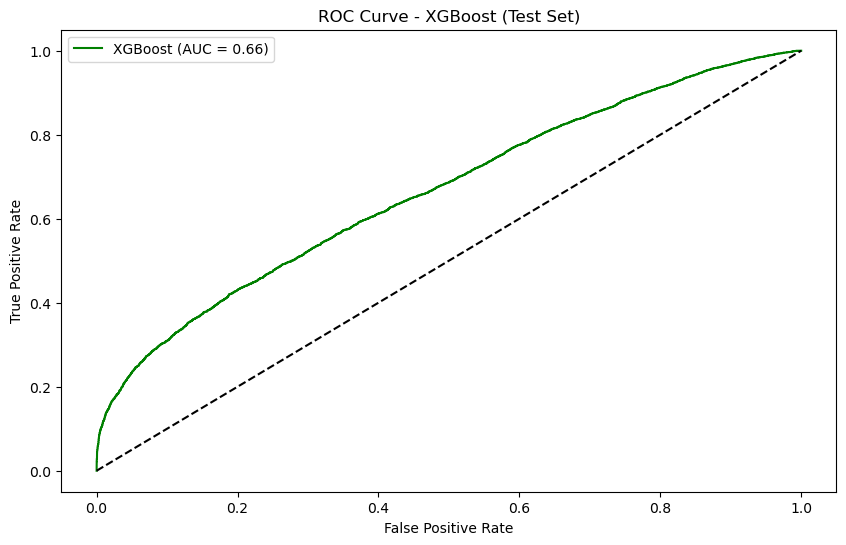

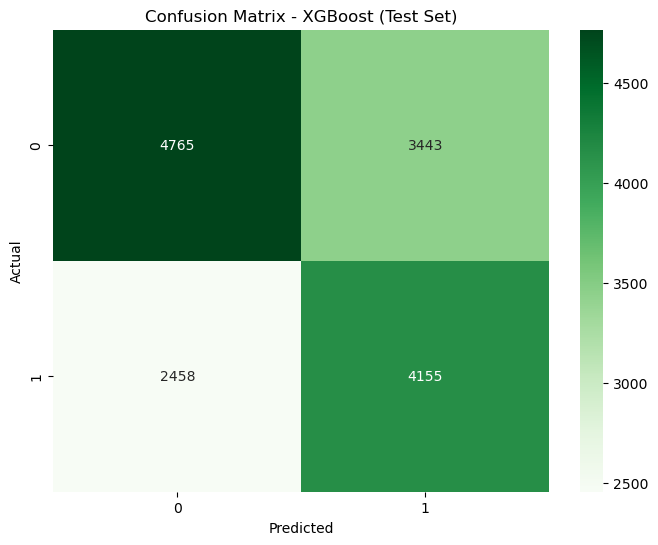

In [267]:
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_test_proba_xgb)

plt.figure(figsize=(10, 6))
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_xgb:.2f})', color='green')
plt.plot([0, 1], [0, 1], 'k--')  # random line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost (Test Set)')
plt.legend(loc='best')
plt.show()

conf_matrix_xgb = confusion_matrix(y_test, y_test_pred_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_xgb, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost (Test Set)')
plt.show()

Conclusions XGBOOST :
Overall Performance: The XGBoost model yielded a 60.18% accuracy on the test set, with 54.69% precision and 62.83% recall for made shots. 
XGBoost’s recall was the highest among the models, meaning it identified nearly two-thirds of all actual made shots. 
Overall, XGBoost showed solid predictive power, especially in capturing true made shots at the expense of some accuracy. 


Trains and optimizes an XGBoost classification model using RandomizedSearchCV to find the best hyperparameters:  
check different parameters for the best results:

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters found: {'subsample': 1.0, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 10, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.6}
Best cross-validation score: 0.6445

Training Set Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.93      0.78     59602
           1       0.83      0.44      0.58     47106

    accuracy                           0.72    106708
   macro avg       0.76      0.69      0.68    106708
weighted avg       0.75      0.72      0.69    106708


Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.88      0.74     14907
           1       0.70      0.36      0.47     11770

    accuracy                           0.65     26677
   macro avg       0.67      0.62      0.61     26677
weighted avg       0.67      0.65      0.62     26677


Test Set 

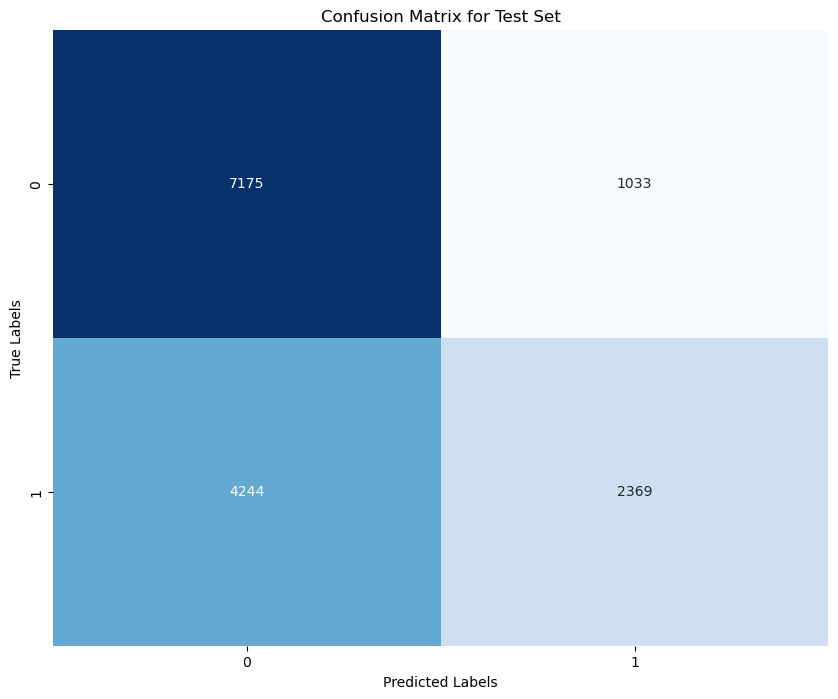


Final Accuracy Scores:
Training accuracy: 0.7153
Validation accuracy: 0.6502
Test accuracy: 0.6440


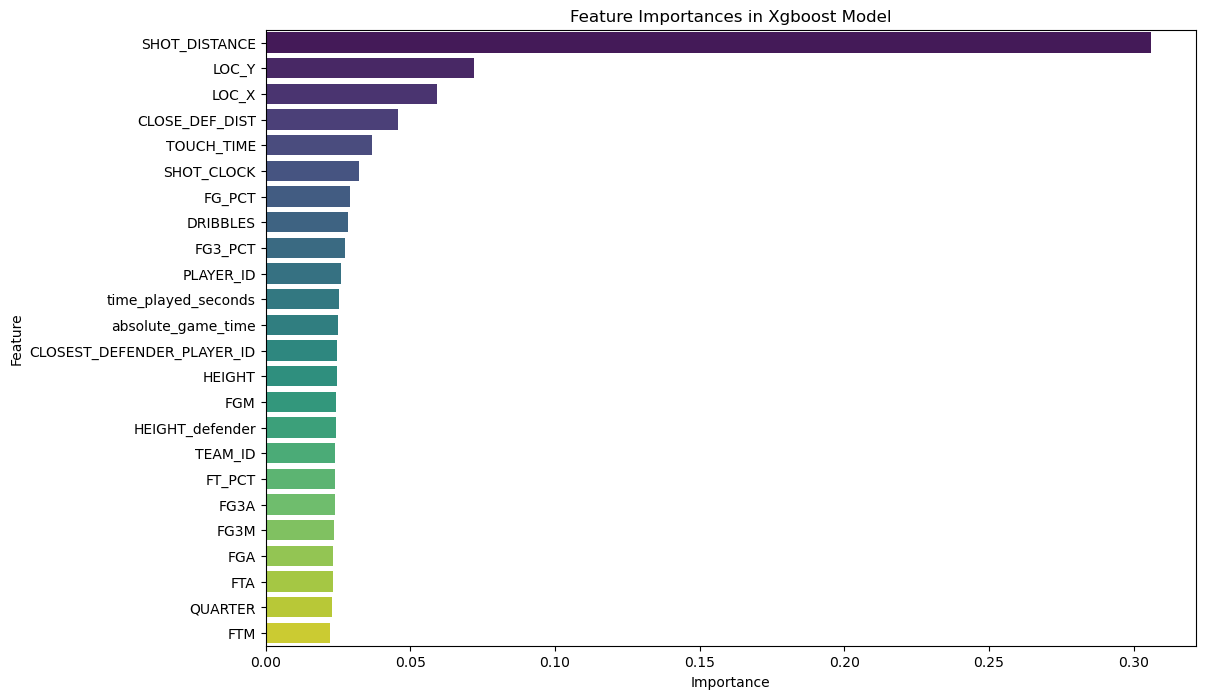

In [467]:
# Define parameter grid for random search
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 6, 8, 10],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4],
    'min_child_weight': [1, 3, 5, 7]
}

# Initialize XGBoost model
xgb_model = XGBClassifier(random_state=42)

# Create RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=12,  # Number of parameter settings sampled
    scoring='accuracy',
    cv=3,  # Number of cross-validation folds
    verbose=4,
    random_state=42,
    n_jobs=-1  # Use all available cores
)

# Fit RandomizedSearchCV to the training data
random_search.fit(X_train, y_train)

# Get the best parameters and best score
best_params = random_search.best_params_
best_score = random_search.best_score_

print(f"Best parameters found: {best_params}")
print(f"Best cross-validation score: {best_score:.4f}")

# Train the model with the best parameters
best_model = XGBClassifier(**best_params, random_state=42)
best_model.fit(X_train, y_train)

# Make predictions on training, validation, and test sets
y_train_pred = best_model.predict(X_train)
y_val_pred = best_model.predict(X_val)
y_test_pred = best_model.predict(X_test)

# Print classification reports
print("\nTraining Set Classification Report:")
print(classification_report(y_train, y_train_pred))

print("\nValidation Set Classification Report:")
print(classification_report(y_val, y_val_pred))

print("\nTest Set Classification Report:")
print(classification_report(y_test, y_test_pred))

# Calculate and plot confusion matrix for test set
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix for Test Set')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Calculate and print accuracy for each set
train_accuracy = best_model.score(X_train, y_train)
val_accuracy = best_model.score(X_val, y_val)
test_accuracy = best_model.score(X_test, y_test)

print(f"\nFinal Accuracy Scores:")
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


# Feature importance visualization (optional)
importances = best_model.feature_importances_

# Create a DataFrame for better visualization
feature_importances = pd.DataFrame({'Feature': features_names, 'Importance': importances})


# Sort the DataFrame by importance
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importances, hue="Feature", palette='viridis', legend=False)
plt.title('Feature Importances in Xgboost Model')
plt.show()


Feature Importance: Being a gradient boosting decision tree model, XGBoost can evaluate which features contribute most to reducing prediction error. 
The distance of the shot was likely a primary influencer – shots taken further from the basket drastically lower the probability of success, so this feature would have a high importance in the model. 
The closest defender distance (how tightly a shooter is guarded) is another crucial factor, XGBoost would learn that a greater defender distance (more openness) increases shot success odds, making it a key split in many boosted trees. 
Temporal features like shot clock time remaining probably ranked next, shots taken in desperation with very low shot clock are harder to make. 
Additionally, the project engineered a “time played” feature, tracking how long the player had been playing when the shot was taken. 
If effective, XGBoost might use this to learn that players tend to shoot worse when they’ve been on the floor for extended stretches, 
though this influence is likely more subtle than distance or defense. 
Overall, XGBoost’s feature importance would highlight that spatial factors (distance to hoop and defender) dominated, followed by time-related factors (shot timing and possibly fatigue)

catboost is a gradient boosting algorithm optimized for handling categorical features efficiently and delivering high performance with minimal tuning:

In [273]:
!pip install catboost

Trains and optimizes a CatBoost classification model using RandomizedSearchCV to find the best hyperparameters. After tuning, it evaluates the model on training, validation, and test sets using accuracy, classification reports, and confusion matrices. Additionally, it visualizes feature importance to understand which features impact predictions the most:

Training CatBoost with RandomizedSearchCV...
Fitting 3 folds for each of 15 candidates, totalling 45 fits
0:	learn: 0.6122315	test: 0.6132998	best: 0.6132998 (0)	total: 55.2ms	remaining: 55.1s
20:	learn: 0.6429415	test: 0.6377029	best: 0.6378903 (18)	total: 1.25s	remaining: 58.4s
40:	learn: 0.6530813	test: 0.6383027	best: 0.6385651 (39)	total: 2.45s	remaining: 57.4s
60:	learn: 0.6630524	test: 0.6388649	best: 0.6390899 (58)	total: 3.69s	remaining: 56.7s
80:	learn: 0.6826573	test: 0.6413015	best: 0.6413015 (80)	total: 5.15s	remaining: 58.4s
100:	learn: 0.7051111	test: 0.6433257	best: 0.6434007 (98)	total: 6.43s	remaining: 57.2s
120:	learn: 0.7225138	test: 0.6445252	best: 0.6445252 (120)	total: 7.67s	remaining: 55.7s
140:	learn: 0.7452019	test: 0.6451250	best: 0.6456873 (138)	total: 8.92s	remaining: 54.3s
160:	learn: 0.7650036	test: 0.6469618	best: 0.6476740 (158)	total: 10.3s	remaining: 53.4s
180:	learn: 0.7831184	test: 0.6478989	best: 0.6488736 (177)	total: 11.5s	remaining: 52.1s
200:	l

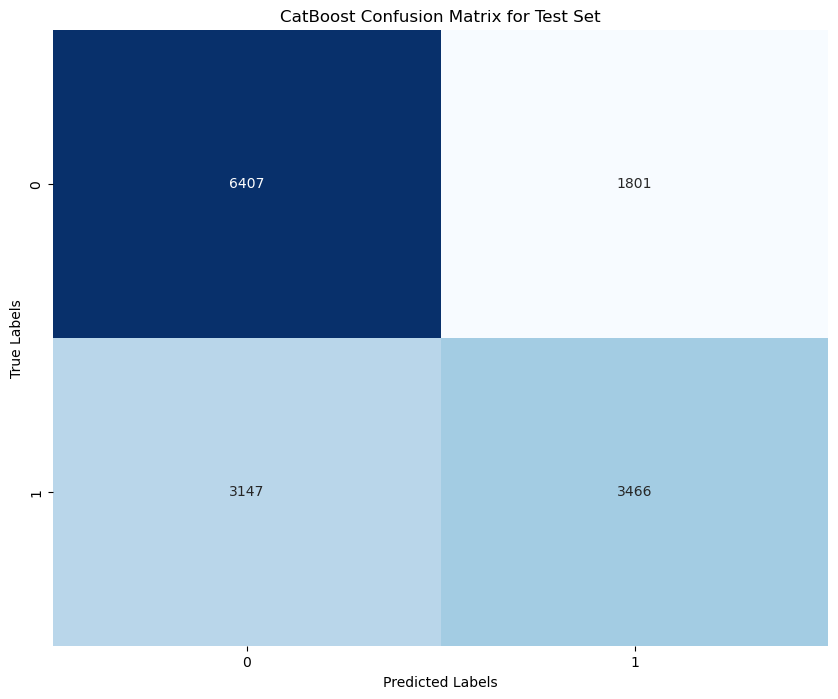


CatBoost Final Accuracy Scores:
Training accuracy: 0.9341
Validation accuracy: 0.6683
Test accuracy: 0.6661


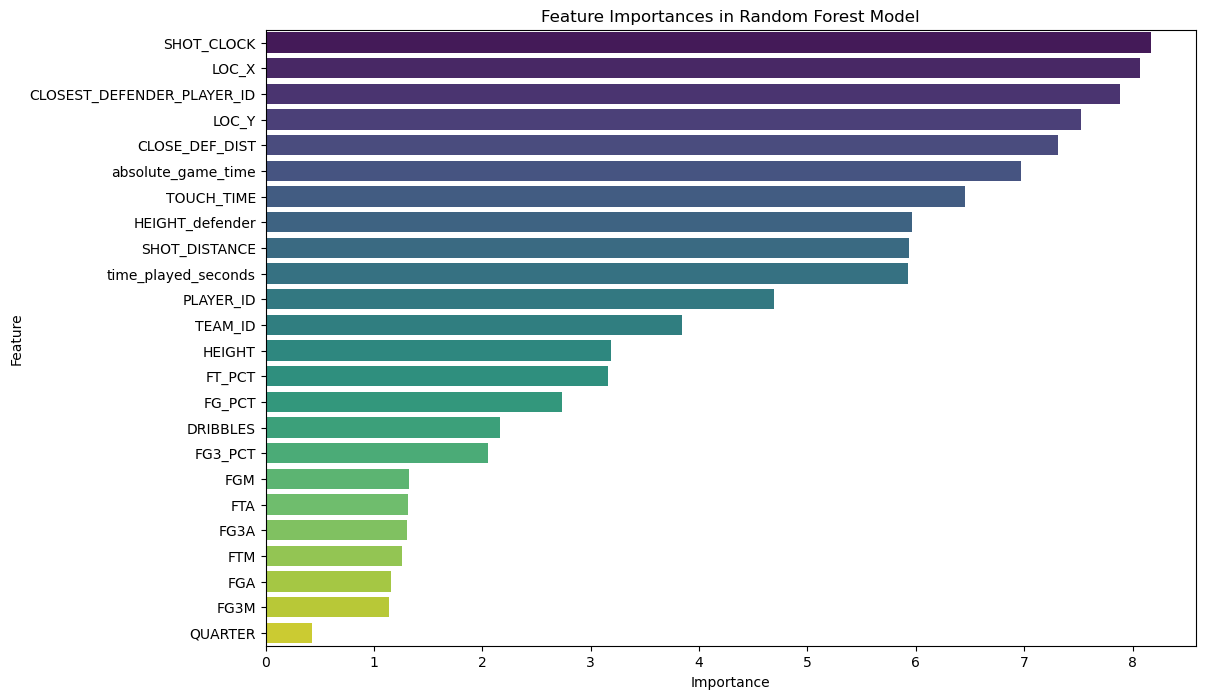

In [468]:
from catboost import CatBoostClassifier

# Define parameter grid for CatBoost random search
catboost_param_grid = {
    'iterations': [100, 200, 500, 1000],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'depth': [4, 6, 8, 10],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'border_count': [32, 64, 128],
    'bagging_temperature': [0, 1, 10],
    'random_strength': [1, 10, 100]
}

# Initialize CatBoost model
cat_model = CatBoostClassifier(
    loss_function='Logloss',
    eval_metric='Accuracy',
    verbose=20,  # Reduce for less output during training
    random_seed=42
)

# Create RandomizedSearchCV for CatBoost
cat_random_search = RandomizedSearchCV(
    estimator=cat_model,
    param_distributions=catboost_param_grid,
    n_iter=15,  # Number of parameter settings sampled
    scoring='accuracy',
    cv=3,  # Number of cross-validation folds
    verbose=4,
    random_state=42,
    n_jobs=-1  # Use all available cores
)

# Fit RandomizedSearchCV to the training data
print("Training CatBoost with RandomizedSearchCV...")
cat_random_search.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50)

# Get the best parameters and best score
cat_best_params = cat_random_search.best_params_
cat_best_score = cat_random_search.best_score_

print(f"\nCatBoost Best parameters found: {cat_best_params}")
print(f"CatBoost Best cross-validation score: {cat_best_score:.4f}")

# Train the model with the best parameters
cat_best_model = CatBoostClassifier(**cat_best_params, random_seed=42, verbose=100)
cat_best_model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50)

# Make predictions on training, validation, and test sets
cat_y_train_pred = cat_best_model.predict(X_train)
cat_y_val_pred = cat_best_model.predict(X_val)
cat_y_test_pred = cat_best_model.predict(X_test)

# Print classification reports
print("\nCatBoost Training Set Classification Report:")
print(classification_report(y_train, cat_y_train_pred))

print("\nCatBoost Validation Set Classification Report:")
print(classification_report(y_val, cat_y_val_pred))

print("\nCatBoost Test Set Classification Report:")
print(classification_report(y_test, cat_y_test_pred))

# Calculate and plot confusion matrix for test set
cat_cm = confusion_matrix(y_test, cat_y_test_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cat_cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('CatBoost Confusion Matrix for Test Set')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.savefig('catboost_confusion_matrix.png')
plt.show()

# Calculate and print accuracy for each set
cat_train_accuracy = accuracy_score(y_train, cat_y_train_pred)
cat_val_accuracy = accuracy_score(y_val, cat_y_val_pred)
cat_test_accuracy = accuracy_score(y_test, cat_y_test_pred)

print(f"\nCatBoost Final Accuracy Scores:")
print(f"Training accuracy: {cat_train_accuracy:.4f}")
print(f"Validation accuracy: {cat_val_accuracy:.4f}")
print(f"Test accuracy: {cat_test_accuracy:.4f}")

# Feature importance visualization
importances = cat_best_model.get_feature_importance()

# Create a DataFrame for better visualization
feature_importances = pd.DataFrame({'Feature': features_names, 'Importance': importances})


# Sort the DataFrame by importance
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importances, hue="Feature", palette='viridis', legend=False)
plt.title('Feature Importances in Random Forest Model')
plt.show()

Conclusions catboost : 

Overall Performance: The CatBoost model delivered the highest accuracy among the models, about 66.61% on the test set. 
It achieved a precision and recall that were relatively well-balanced: approximately 66% precision and 52% recall for predicting made shots.


Feature Importance:  
CatBoost, like XGBoost, is a gradient boosting tree model and can evaluate feature importances.  
Shot distance to the basket was among the top factors – the model learned that the farther the shot, the lower the probability of a make, significantly affecting the prediction.  
Similarly, closest defender distance was highly influential – an open shot (defender far away) is much more likely to go in than a tightly contested shot, and CatBoost would heavily weight this in its decisions.  
In addition, shot clock and time remaining factors play a role: CatBoost would pick up that shots taken under rushed conditions.  
CatBoost also benefited from built-in mechanisms to combat overfitting, such as symmetric tree structures and ordered boosting.  
The use of early stopping during training (stop after 50 rounds of no improvement) ensured it didn’t overfit.

### The value of Running Three Tree-Based Algorithms (Random Forest, XGBoost, CatBoost) in our shot prediction Project : 
- Differences in Learning Approach & Bias-Variance Tradeoff - Each algorithm learns patterns differently, which helps you understand your data better :
  - Random Forest: Uses bagging (bootstrap aggregation), where multiple decision trees are trained independently on different subsets of the data and then averaged.
    This helps reduce variance but may still struggle with highly imbalanced or sparse data.
   - XGBoost: Uses boosting, meaning trees are built sequentially, and each new tree corrects the mistakes of the previous ones.
  This method significantly reduces bias, leading to higher accuracy, but at the cost of increased risk of overfitting.
    - CatBoost: Also uses boosting but specializes in categorical feature encoding and ordered boosting, making it especially effective for
  datasets with categorical variables.
  It tends to generalize better than XGBoost on unseen data.
- Feature Importance and Interpretability - Even though all three models rank feature importance, they do it slightly differently:
  -  Random Forest ranks importance based on how often a feature reduces impurity across all trees.
   -   XGBoost uses gain-based importance, meaning it focuses on how much each feature contributes to reducing error.
    -   CatBoost provides ordered boosting, which helps deal with target leakage and categorical features better.
-    Handling Different Data Characteristics - Each model handles different challenges in the dataset:
     - Random Forest: Handles missing values and outliers well but might struggle with feature importance when some variables dominate others.
      - XGBoost: Handles imbalanced data better due to its boosting mechanism.
       - CatBoost: Works well when dealing with categorical variables (like TEAM_ID or PLAYER_ID), reducing preprocessing effort.
- Model Selection & Hyperparameter Tuning - By testing all three, you can:
  - Find the best model for accuracy, F1-score, or AUC.
   - Identify how sensitive each model is to hyperparameters—some models might need more fine-tuning than others.
    - Choose the most efficient model in terms of training time vs. predictive power.

## General project conclusions : 
The project provided valuable insight into what influences shot success and demonstrated that predictive modeling can capture many of those insights quantitatively. 
We confirmed that shot selection matters greatly – distance and defense can make or break the odds of scoring. 
The best model (CatBoost) can serve as a tool to evaluate shot quality in hindsight or even suggest the probability of success in real-time. 0 While its predictions are not perfect (there is still a lot of randomness in sports), they are significantly better than chance and better than simpler heuristics. This kind of model could be used by teams to analyze shot attempts post-game (to identify if they are getting good looks or forcing tough shots) or potentially during games for quick decision support. The modeling process also highlighted the need for careful consideration of which metric to optimize and the value of domain-driven feature engineering. Future work can build on this foundation to create even more accurate and useful basketball analytics models, perhaps integrating more aspects of the game and tailoring the outputs to coaching decisions. The evolution of this project could ultimately contribute to smarter shot selection and better understanding of the game – a win for data-driven sports strategy.

### Access to  nba data  :
During this project, we explored potential additional datasets that could significantly improve shot prediction accuracy.  
One of the most valuable sources would be player movement data collected from wearable sensors, which could help analyze shooting angles, body positioning, and even estimate fatigue levels more precisely.  
For example, heart rate data or biometric metrics recorded in real time could indicate a player’s level of exhaustion and its impact on shot accuracy.

Another promising data source is tracking data from game cameras, which continuously follow and analyze player movements, defensive positioning, and shot trajectories.  
These advanced computer vision systems could provide detailed biomechanical insights that are currently unavailable in traditional box score statistics.

Unfortunately, the NBA does not publicly release these advanced datasets, keeping them for internal use by teams and analysts.  
As a result, we were unable to incorporate them into our prediction model, limiting our ability to leverage real-time movement and physiological data for enhanced accuracy.



## Additional Basketball Insights That Can Be Derived from our Dataset : 
#### Player Efficiency in Different Game Contexts : 
- Clutch Performance: By analyzing absolute_game_time and shot outcomes in the last minutes of close games, we can assess which players perform best under pressure.
- Fatigue Impact: Using time_played_seconds, we can evaluate how player performance changes as they log more minutes in a game.
- Quarter-based Performance: By segmenting shots by QUARTER, we can identify if players or teams perform differently as the game progresses.
#### Defensive Impact on Shot Selection & Accuracy : 
- Defensive Pressure Effect: Using CLOSE_DEF_DIST, we can analyze how the presence of a defender influences shooting efficiency.
- Defensive Schemes & Shot Locations: Combining LOC_X, LOC_Y, and defensive data, we can see whether certain defensive strategies force players into less efficient shots.
- Shot Contestation Impact: We could classify shots as "contested" vs. "open" and evaluate how shooting percentages change under different defensive conditions.
#### Team Offensive Strategies & Shot Distribution : 
- shot Selection Patterns: Analyzing SHOT_DISTANCE, LOC_X, LOC_Y, and shot outcome can reveal if a team prioritizes mid-range shots, three-pointers, or points in the paint.
- Shot Clock Usage: Investigating SHOT_CLOCK data could show which teams take early vs. late shots and whether they are more efficient in certain shot clock situations.
- Fast Break vs. Half-Court Play: If play-by-play data is available, we can analyze whether a team is more efficient in transition vs. set plays.
#### Player-Specific Tendencies & Strengths : 
- Preferred Shooting Spots: By mapping a player's successful shots using LOC_X, LOC_Y, we can determine their hot zones.
- Dribble Dependency: Analyzing DRIBBLES before a shot can indicate whether a player is more effective in catch-and-shoot vs. isolation situations.
- Touch Time & Decision Speed: TOUCH_TIME can be used to understand which players take quick shots vs. those who hold the ball longer before attempting a shot.


